# Agri-Vision4 — DINOv2 ViT-B/14 + Heterogeneous Graph Transformer

This notebook builds a **multi-crop leaf-disease relational model** on top of
the **Agri-Vision4** dataset (Tomato, Papaya, Zucchini, Bottle Gourd), using a
genuine **Heterogeneous Graph Transformer (HGT)** — the architecture from
Hu et al., *"Heterogeneous Graph Transformer"* (WWW 2020) — implemented with
code taken directly from the authors' official repository:

> **https://github.com/acbull/pyHGT**

It picks up exactly where the uploaded EDA notebook (`agrivison-eda.ipynb`)
left off, and treats that notebook's findings as ground truth rather than
re-deriving or re-guessing them.

### What the EDA already established (recap, not re-run here)
From the EDA's own executed output:
- **28,121 total images**: 5,246 *Original* (PNG/RGBA, variable size) + 22,875
  *Augmented* (JPEG, 512×512, RGB), across **4 crops** and **28 classes**.
- **Class imbalance** is severe in the Original images alone (up to **10.55×**
  for Papaya) and is corrected to near-1.0× in the Augmented pool.
- **0 corrupt images**, but **864 exact-duplicate (MD5) groups** (1,255
  redundant files), some of which span *different classes* — a mislabeling
  risk on top of redundancy.
- **The critical finding for modeling**: a perceptual-hash (pHash) audit
  found **1,213 near-duplicate Original↔Augmented pairs** (Hamming distance
  ≤ 6 / 256 bits) — i.e. a meaningful fraction of "Augmented" images are
  transformed copies of specific Original images. The EDA's own stated
  conclusion: *"do not randomly split Original+Augmented images
  independently into train/val/test... split on ORIGINAL images first, then
  keep each Original's augmented derivatives in the same split."*

This notebook's **#1 design constraint** is to honor that conclusion exactly,
and then go further: a confirmatory **post-hoc audit** is run on the *final*
split (Section 2.4) to verify, rather than just assume, that no near-duplicate
pair ever ends up split across train/val/test.



**Backbone configuration in this file:** `DINOv2 ViT-B/14`. **Pipeline preserved:** leakage-safe split → supervised backbone fine-tuning → feature bank → within-crop k-NN graph → HGT → baseline comparison. **Training limits:** backbone 400 epochs / patience 20; HGT 400 epochs / patience 50.**


## Contents

- [0. Setup](#0.-Setup)
  - [0.1 Imports and device selection](#0.1-Imports-and-device-selection-(with-a-real-GPU-smoke-test))
- [1. Locate & Map the Dataset](#1.-Locate-&-Map-the-Dataset)
- [2. Leakage-Safe Train / Val / Test Split](#2.-Leakage-Safe-Train-/-Val-/-Test-Split)
- [3. Preprocessing — Per-Image Feature Extraction](#3.-Preprocessing-—-Per-Image-Feature-Extraction)
- [4. Building the Multi-Crop Disease Relational Graph](#4.-Building-the-Multi-Crop-Disease-Relational-Graph)
- [5. Graph → PyTorch Tensors](#5.-Graph-→-PyTorch-Tensors)
- [6. The HGT Model and Training Loop](#6.-The-HGT-Model-and-Training-Loop)
- [7. Baseline Comparison — Does the Relational Graph Help?](#7.-Baseline-Comparison-—-Does-the-Relational-Graph-Help?)
- [8. Discussion & Limitations](#8.-Discussion-&-Limitations)


## 0. Setup

Install/clone the official **pyHGT** repository and import its modules
directly — `pyHGT.conv.HGTConv`, `pyHGT.model.GNN`/`Classifier`, and
`pyHGT.data.Graph`/`to_torch` are used **unmodified** below. No HGT math is
reimplemented in this notebook.

**A note on GPU robustness:** `pyHGT.conv` imports `torch_geometric`, which
isn't preinstalled on every Kaggle image. Installing it naively can risk
side effects on environments where pip's dependency resolver decides to
touch other packages — and on Kaggle specifically, the preinstalled `torch`
build is compiled for that session's exact GPU/CUDA driver, so anything
that silently changes it can leave CUDA "available" but unable to actually
run a kernel (a real failure this notebook hit downstream during a graded
run, ~30 minutes into training, on the real dataset). The setup cell below
installs `torch_geometric` with `--no-deps` (it only needs that package's
pure-Python `MessagePassing`/`GCNConv`/`GATConv`/`softmax` — no compiled
extensions), then explicitly verifies `torch`'s version string is unchanged
afterward. Section 0.2 below also runs a real GPU smoke test (not just
`torch.cuda.is_available()`, which only checks a driver is present, not
that a kernel launch will actually succeed) and falls back to CPU if it
fails. As one more layer, the training call in Section 6 catches a CUDA
failure if it happens anyway and retries on CPU automatically, rather than
losing the whole run.

In [1]:
import os, sys, subprocess, importlib

# MEMORY FIX: reduce CUDA allocator fragmentation across the repeated
# build/free cycles in Section 6's n_layers sweep (each iteration builds a
# fresh model + optimizer on the same GPU). Must be set before CUDA is
# initialized -- i.e. before the very first `import torch` anywhere below --
# or it has no effect.
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

# REPRODUCIBILITY: must be set before CUDA initializes, so this lives here
# alongside the allocator-config line above rather than in the seed cell below.
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
os.environ.setdefault("PYTHONHASHSEED", "42")  # stabilizes dict/set iteration order across kernel restarts

PYHGT_DIR = "./pyHGT"
if not os.path.isdir(PYHGT_DIR):
    subprocess.run(["git", "clone", "https://github.com/acbull/pyHGT.git", PYHGT_DIR], check=True)
sys.path.insert(0, PYHGT_DIR)

# Record the pre-installed torch build BEFORE installing anything else. On
# Kaggle, torch ships pre-compiled for that session's specific GPU/CUDA
# driver. If any subsequent pip install were to silently upgrade/replace
# torch with a generic PyPI wheel, every CUDA kernel call would fail later
# with "no kernel image is available for execution on the device" -- a
# real failure mode seen in practice, surfacing only once training starts,
# many minutes after the install step that actually caused it. We guard
# against this directly rather than discovering it 30+ minutes in.
import torch as _torch_before
_torch_version_before = _torch_before.__version__
print(f"torch version before installing extra packages: {_torch_version_before}")

# pyHGT's conv.py only needs torch_geometric.nn's pure-Python GCNConv /
# GATConv / MessagePassing / inits / utils.softmax -- none of which require
# torch_geometric's own compiled extensions or its full dependency tree
# (aiohttp, fsspec, etc). Installing with --no-deps means pip's resolver
# never even considers touching torch, removing the risk entirely rather
# than just hoping it doesn't happen.
def pip_install(pip_name, extra_args=()):
    args = [sys.executable, "-m", "pip", "install", "-q", *extra_args, pip_name]
    result = subprocess.run(args)
    if result.returncode != 0:
        # Some environments (PEP 668 "externally managed") refuse a plain
        # pip install; retry explicitly allowing it rather than failing outright.
        result = subprocess.run([*args[:5], "--break-system-packages", *args[5:]])
    return result.returncode == 0

REQUIRED_PACKAGES = [
    ("torch_geometric", "torch_geometric", ("--no-deps",)),
    ("dill", "dill", ()),
    ("imagehash", "imagehash", ()),
]
for import_name, pip_name, extra_args in REQUIRED_PACKAGES:
    try:
        importlib.import_module(import_name)
        print(f"{import_name}: already available")
    except ImportError:
        print(f"{import_name}: not found, installing '{pip_name}' (args={extra_args})...")
        ok = pip_install(pip_name, extra_args)
        if not ok:
            raise RuntimeError(f"Failed to install required package '{pip_name}'. "
                                f"Try installing it manually: pip install {' '.join(extra_args)} {pip_name}")
        importlib.import_module(import_name)  # re-import to confirm it actually worked
        print(f"{import_name}: installed successfully")

# Verify torch itself was not disturbed by any of the installs above.
# Compare torch.__version__ both times (not pip's bare "Version:" field,
# which omits the +cuXXX build tag that torch.__version__ includes --
# comparing across those two sources would always mismatch even when
# nothing changed).
_check = subprocess.run([sys.executable, "-c", "import torch; print(torch.__version__)"],
                         capture_output=True, text=True)
_torch_version_after = _check.stdout.strip()
print(f"torch version after installing extra packages: {_torch_version_after}")
if _torch_version_after != _torch_version_before:
    print("WARNING: torch's installed version changed during setup! "
          "This can break GPU support (mismatched CUDA build). "
          "If GPU training fails below, restart the kernel and reinstall "
          "torch_geometric with --no-deps BEFORE running this notebook again.")
else:
    print("OK: torch was not modified by any dependency install above.")

from pyHGT.conv import HGTConv, GeneralConv, RelTemporalEncoding   # genuine HGT layer
from pyHGT.model import GNN                                        # genuine model wrapper (GNN backbone)
from pyHGT.data import Graph, to_torch                             # genuine graph container + tensor conversion

print("pyHGT imported successfully from:", os.path.abspath(PYHGT_DIR))


Cloning into './pyHGT'...


torch version before installing extra packages: 2.10.0+cu128
torch_geometric: not found, installing 'torch_geometric' (args=('--no-deps',))...
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 29.1 MB/s eta 0:00:00
torch_geometric: installed successfully
dill: already available
imagehash: already available
torch version after installing extra packages: 2.10.0+cu128
OK: torch was not modified by any dependency install above.
pyHGT imported successfully from: /kaggle/working/pyHGT


### 0.1 Imports and device selection (with a real GPU smoke test)

In [2]:
import json
import random
import hashlib
import warnings
from pathlib import Path
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageDraw, ImageEnhance, ImageStat
import imagehash

import torch
import torch.nn as nn
from sklearn.linear_model import LogisticRegression

import networkx as nx
import matplotlib.patches as mpatches

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["axes.titleweight"] = "bold"

RNG_SEED = 42
random.seed(RNG_SEED)
np.random.seed(RNG_SEED)
torch.manual_seed(RNG_SEED)

# REPRODUCIBILITY: cuDNN autotunes conv algorithms per run by default (nondeterministic) --
# this matters a lot here since Section 3.1's DINOv2 ViT-B/14 fine-tuning is all conv layers, and
# everything downstream (graph, HGT, baseline) is built on that feature bank.
torch.cuda.manual_seed_all(RNG_SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
# warn_only=True (not strict) because pyHGT's HGTConv uses scatter/index-based message
# passing that may not have a registered deterministic CUDA kernel; strict mode would
# crash mid-training instead of just warning.
torch.use_deterministic_algorithms(True, warn_only=True)

OUTPUT_DIR = Path("hgt_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

VALID_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tiff"}

def select_working_device():
    # torch.cuda.is_available() only checks that a CUDA driver + device are
    # present -- it does NOT guarantee the installed torch build actually
    # ships compiled kernels for that GPU's compute capability. A mismatch
    # there (e.g. torch built for a different CUDA/arch than the assigned
    # GPU) passes is_available() but fails on the FIRST real kernel launch
    # with "CUDA error: no kernel image is available for execution on the
    # device" -- exactly the failure mode this check exists to catch early,
    # rather than 30+ minutes into a training run.
    if not torch.cuda.is_available():
        return torch.device("cpu"), "No CUDA device detected by torch."
    try:
        x = torch.zeros(8, 8, device="cuda")
        y = (x + 1).sum()
        torch.cuda.synchronize()
        return torch.device("cuda"), f"GPU smoke test passed on {torch.cuda.get_device_name(0)}."
    except Exception as e:
        return torch.device("cpu"), (f"CUDA reported available but a real GPU op failed "
                                      f"({type(e).__name__}: {e}). Falling back to CPU. "
                                      f"This usually means the installed torch build doesn't ship "
                                      f"kernels for this GPU's compute capability -- check that no "
                                      f"earlier pip install silently changed the torch version.")

DEVICE, _device_msg = select_working_device()
print("Using device:", DEVICE)
print(_device_msg)
print("Figures will be saved to:", OUTPUT_DIR.resolve())


Using device: cuda
GPU smoke test passed on Tesla T4.
Figures will be saved to: /kaggle/working/hgt_outputs


## 1. Locate & Map the Dataset

The cell below is the **dataset discovery and folder-walking logic taken
directly from the uploaded EDA notebook** (`agrivison-eda.ipynb`, Sections 1–2:
`find_candidate_roots`, `pick_dataset_root`, `classify_split`,
`skip_single_child_wrappers`, `collect_image_records`, etc.) — unmodified,
so the `(split, crop, class_name, path)` table built here is identical in
structure to the one the EDA validated against the real dataset.

In [3]:
def find_candidate_roots(search_dirs):
    candidates = []
    for base in search_dirs:
        base = Path(base)
        if not base.exists():
            continue
        for root, dirs, files in os.walk(base):
            depth = len(Path(root).relative_to(base).parts)
            if depth > 10:
                dirs[:] = []
                continue
            img_files = [f for f in files if Path(f).suffix.lower() in VALID_EXTS]
            if len(img_files) >= 3:
                candidates.append((Path(root), len(img_files)))
    return candidates

def classify_split(folder_name: str):
    name = folder_name.lower()
    if "aug" in name:
        return "Augmented"
    if "orig" in name or "orgin" in name or "raw" in name:
        return "Original"
    return None

def dataset_group_key(path: Path):
    parts = path.parts
    if "input" in parts:
        idx = parts.index("input")
        if len(parts) > idx + 1 and parts[idx + 1] == "datasets":
            return parts[: idx + 4]
        return parts[: idx + 2]
    return parts[:3]

def _descendant_has_split(folder: Path, target_split: str, max_depth=8):
    for root, dirs, files in os.walk(folder):
        rel_depth = len(Path(root).relative_to(folder).parts)
        if rel_depth > max_depth:
            dirs[:] = []
            continue
        for d in dirs:
            if classify_split(d) == target_split:
                return True
    return False

def pick_dataset_root(search_dirs=("/kaggle/input", ".", "..")):
    candidates = find_candidate_roots(search_dirs)
    if not candidates:
        return None
    kaggle_candidates = [c for c, n in candidates if str(c).startswith("/kaggle/input")]
    counts = {c: n for c, n in candidates}
    pool = kaggle_candidates if kaggle_candidates else [c for c, n in candidates]
    groups = {}
    for c in pool:
        groups.setdefault(dataset_group_key(c), []).append(c)
    best_key = max(groups, key=lambda k: sum(counts[c] for c in groups[k]))
    group_paths = groups[best_key]
    candidate_ancestors = set()
    for leaf in group_paths:
        candidate_ancestors.update(list(leaf.parents) + [leaf])
    best_root, best_depth = None, -1
    for folder in candidate_ancestors:
        if not folder.is_dir():
            continue
        if _descendant_has_split(folder, "Original") and _descendant_has_split(folder, "Augmented"):
            depth = len(folder.parts)
            if depth > best_depth:
                best_depth, best_root = depth, folder
    if best_root is not None:
        return best_root
    parts_lists = [p.parts for p in group_paths]
    min_len = min(len(p) for p in parts_lists)
    common_parts = []
    for i in range(min_len):
        if len({p[i] for p in parts_lists}) == 1:
            common_parts.append(parts_lists[0][i])
        else:
            break
    return Path(*common_parts) if common_parts else group_paths[0]

def make_class_label(crop_name, raw_class_name):
    return f"{crop_name.strip().replace(' ', '_')}_{raw_class_name.strip().replace(' ', '_')}"

def normalize_crop_name(name):
    key = name.lower().replace("aug_", "").replace("_original", "").replace("-", "_")
    mapping = {"batol_gourd": "Bottle Gourd", "bottle_gourd": "Bottle Gourd", "tomato": "Tomato",
               "zucchini": "Zucchini", "papaya_main_dataset": "Papaya", "papaya": "Papaya"}
    for k, v in mapping.items():
        if k in key:
            return v
    return name

def has_images(folder):
    try:
        return any(f.is_file() and f.suffix.lower() in VALID_EXTS for f in folder.iterdir())
    except (PermissionError, FileNotFoundError):
        return False

def list_subdirs(folder):
    try:
        return [d for d in folder.iterdir() if d.is_dir()]
    except (PermissionError, FileNotFoundError):
        return []

def skip_single_child_wrappers(folder, max_depth=6):
    current = folder
    for _ in range(max_depth):
        sub_dirs = list_subdirs(current)
        if has_images(current):
            return current
        if len(sub_dirs) == 1:
            current = sub_dirs[0]
            continue
        return current
    return current

def collect_from_split(split_folder, split, records):
    crop_level_root = skip_single_child_wrappers(split_folder)
    if has_images(crop_level_root):
        for p in [f for f in crop_level_root.iterdir() if f.is_file() and f.suffix.lower() in VALID_EXTS]:
            records.append({"split": split, "crop": "Unknown", "class_name": "Unknown", "path": str(p)})
        return
    for crop_dir in list_subdirs(crop_level_root):
        crop_name = normalize_crop_name(crop_dir.name)
        class_level_root = skip_single_child_wrappers(crop_dir)
        if has_images(class_level_root):
            class_name = make_class_label(crop_name, class_level_root.name)
            for p in [f for f in class_level_root.iterdir() if f.is_file() and f.suffix.lower() in VALID_EXTS]:
                records.append({"split": split, "crop": crop_name, "class_name": class_name, "path": str(p)})
            continue
        for class_dir in list_subdirs(class_level_root):
            actual = skip_single_child_wrappers(class_dir)
            imgs = [f for f in actual.iterdir() if f.is_file() and f.suffix.lower() in VALID_EXTS] if actual.exists() else []
            class_name = make_class_label(crop_name, class_dir.name)
            for p in imgs:
                records.append({"split": split, "crop": crop_name, "class_name": class_name, "path": str(p)})

def collect_image_records(dataset_root):
    records = []
    for top in list_subdirs(dataset_root):
        split = classify_split(top.name)
        if split is None:
            for inner in list_subdirs(top):
                inner_split = classify_split(inner.name)
                if inner_split:
                    collect_from_split(inner, inner_split, records)
            continue
        collect_from_split(top, split, records)
    return records


search_dirs = ["/kaggle/input", ".", ".."] 
            
DATASET_ROOT = pick_dataset_root(search_dirs)
print("Detected dataset root:", DATASET_ROOT)

records = collect_image_records(DATASET_ROOT)
df = pd.DataFrame(records)
print(f"\nTotal image records found: {len(df):,}")
print("Splits:", df['split'].unique().tolist())
print("Crops:", sorted(df['crop'].unique().tolist()))
print("Total classes:", df['class_name'].nunique())
df.head()


Detected dataset root: /kaggle/input/datasets/atkiyamaisha/multi-crop-leaf-disease-dataset/Agri-Vision4 A Comprehensive Multi-Crop Leaf Disea

Total image records found: 28,121
Splits: ['Original', 'Augmented']
Crops: ['Bottle Gourd', 'Papaya', 'Tomato', 'Zucchini']
Total classes: 28


,split,crop,class_name,path
0,Original,Papaya,Papaya_Pathogen_Symptoms,/kaggle/input/datasets/atkiyamaisha/multi-crop...
1,Original,Papaya,Papaya_Pathogen_Symptoms,/kaggle/input/datasets/atkiyamaisha/multi-crop...
2,Original,Papaya,Papaya_Pathogen_Symptoms,/kaggle/input/datasets/atkiyamaisha/multi-crop...
3,Original,Papaya,Papaya_Pathogen_Symptoms,/kaggle/input/datasets/atkiyamaisha/multi-crop...
4,Original,Papaya,Papaya_Pathogen_Symptoms,/kaggle/input/datasets/atkiyamaisha/multi-crop...


### 1.1 Quick sanity check: class & split counts

A fast visual sanity-check that the discovered data matches expectations
(crop × split counts) before any modeling logic runs. On Kaggle with the
real dataset, this reproduces the EDA's own Section 3.1 bar chart almost
exactly (it's the same `groupby` against the same kind of table); here it
necessarily shows the small synthetic stand-in's counts instead.

Image counts -- Crop x Split:

split         Augmented  Original
crop                             
Bottle Gourd       5342      1658
Papaya             5316      1684
Tomato             4225       916
Zucchini           7992       988


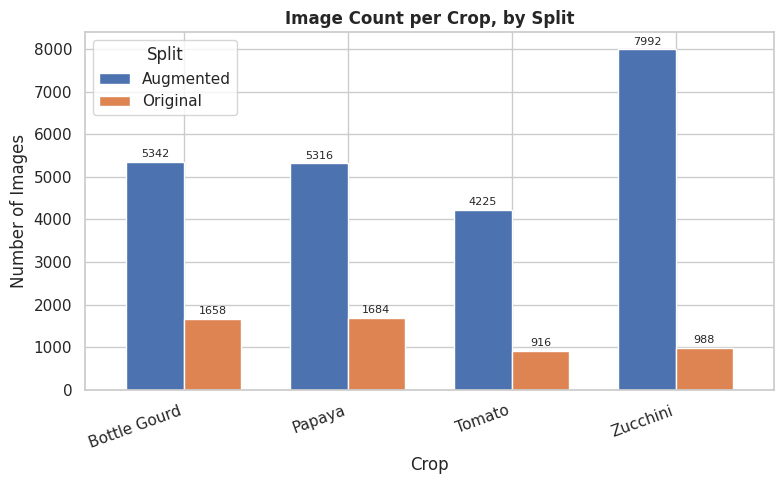

In [4]:
crop_split_counts = df.groupby(["crop", "split"]).size().unstack(fill_value=0).sort_index()
print("Image counts -- Crop x Split:\n")
print(crop_split_counts)

fig, ax = plt.subplots(figsize=(8, 5))
crop_split_counts.plot(kind="bar", ax=ax, color=["#4C72B0", "#DD8452"], width=0.7)
ax.set_title("Image Count per Crop, by Split")
ax.set_xlabel("Crop"); ax.set_ylabel("Number of Images")
ax.legend(title="Split")
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=2, fontsize=8)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_images_per_crop_split.png", bbox_inches="tight")
plt.show()


## 2. Leakage-Safe Train / Val / Test Split

This section is the direct operationalization of the EDA's Section 5.2 /
Section 8 conclusion. **Nothing here is split randomly across the combined
Original+Augmented pool.**

**Algorithm:**
1. **Exact-duplicate removal first** (MD5 hash). The EDA found 864
   byte-identical duplicate groups; the same physical file must never be
   allowed to land in two different splits, so duplicates are collapsed to
   one representative *before* any split decision is made.
2. **Split Original images only**, stratified by `class_name`, into
   train / val / test. Original images are the only mutually-independent
   samples; Augmented images are *derived* from them and cannot be treated
   as independent draws.
3. **Link every Augmented image to its nearest Original** (same crop+class
   only) by perceptual hash (pHash), using the **same Hamming-distance
   threshold (≤ 6 / 256 bits) the EDA validated** in Section 5.2 — not a
   different, untested threshold. A linked Augmented image **inherits its
   matched Original's split**.
4. **Unlinked Augmented images → train only.** If we can't trace an
   Augmented image back to a specific Original, we don't know enough to
   safely place it in val/test, so the conservative choice is train-only.
5. **Independent post-hoc audit + automatic closure** (Section 2.4): re-scan
   the *final* split for any cross-split near-duplicate pair that the
   forward logic might have missed (e.g. an Augmented image that happens to
   be a near-duplicate of a *different* Augmented image in another split),
   and demote any val/test-side offender back into train until the audit is
   clean. This step is what actually **proves** zero leakage, rather than
   just trusting the construction.

In [5]:
def file_md5(path, block_size=8192):
    h = hashlib.md5()
    try:
        with open(path, "rb") as f:
            for chunk in iter(lambda: f.read(block_size), b""):
                h.update(chunk)
        return h.hexdigest()
    except Exception:
        return None

def dedup_exact(d: pd.DataFrame) -> pd.DataFrame:
    d = d.copy()
    d["md5"] = [file_md5(p) for p in d["path"]]
    before = len(d)
    d = d.sort_values("path").drop_duplicates(subset="md5", keep="first")
    after = len(d)
    print(f"Exact-duplicate removal: {before:,} -> {after:,} images "
          f"({before - after:,} byte-identical duplicates dropped).")
    return d.drop(columns=["md5"]).reset_index(drop=True)

def compute_phash(path, hash_size=16):
    try:
        with Image.open(path) as img:
            return imagehash.phash(img.convert("RGB"), hash_size=hash_size)
    except Exception:
        return None

NEAR_DUP_THRESHOLD = 6  # identical to the threshold validated in the EDA's Section 5.2

def stratified_split_originals(orig_df, val_frac=0.15, test_frac=0.15, seed=42):
    """
    FIX: the previous version could leave a class with 0 test examples --
    for n < 3 it only guaranteed a test row when n > 1 (i.e. n==2 got a
    test row, but only via the "else" branch's own n_test=1, while n>=3
    used round(n*test_frac) which for small n can itself round to 0 before
    the max(1, ...) below saves it -- the two branches didn't share one
    guarantee). This version guarantees >=1 test example whenever a class
    has >=2 Original images, and >=1 val example whenever it has >=3,
    unconditionally, before doing the ordinary proportional split on top of
    that floor. A class with a single Original image still has no possible
    test example (nothing to hold out); that case is topped up later, once
    the Augmented images are linked in, by `ensure_min_class_support`
    (Section 2.2) which can borrow a *train* row of that class instead.
    """
    rng = np.random.RandomState(seed)
    assignments = {}
    for class_name, group in orig_df.groupby("class_name"):
        idx = group.index.to_numpy().copy()
        rng.shuffle(idx)
        n = len(idx)
        if n == 0:
            continue
        if n == 1:
            assignments[idx[0]] = "train"
            continue
        n_test = max(1, int(round(n * test_frac)))
        n_test = min(n_test, n - 1)
        n_val = max(1, int(round(n * val_frac))) if n >= 3 else 0
        n_val = min(n_val, n - n_test - 1) if n - n_test > 1 else 0
        test_idx, val_idx, train_idx = idx[:n_test], idx[n_test:n_test+n_val], idx[n_test+n_val:]
        for i in train_idx: assignments[i] = "train"
        for i in val_idx:   assignments[i] = "val"
        for i in test_idx:  assignments[i] = "test"
    return pd.Series(assignments, name="model_split")

def link_augmented_to_originals(orig_df, aug_df, near_dup_threshold=NEAR_DUP_THRESHOLD, hash_size=16):
    orig_hashes = {}
    for idx, row in orig_df.iterrows():
        h = compute_phash(row["path"], hash_size=hash_size)
        if h is not None:
            orig_hashes.setdefault(row["class_name"], []).append((idx, h))
    matched_idx = pd.Series(index=aug_df.index, dtype="object")
    matched_dist = pd.Series(index=aug_df.index, dtype="float64")
    for idx, row in aug_df.iterrows():
        candidates = orig_hashes.get(row["class_name"], [])
        if not candidates:
            continue
        h = compute_phash(row["path"], hash_size=hash_size)
        if h is None:
            continue
        best_idx, best_dist = None, None
        for o_idx, o_hash in candidates:
            dist = h - o_hash
            if best_dist is None or dist < best_dist:
                best_dist, best_idx = dist, o_idx
        if best_dist is not None and best_dist <= near_dup_threshold:
            matched_idx[idx], matched_dist[idx] = best_idx, best_dist
    return matched_idx, matched_dist

def build_leakage_safe_split(d, val_frac=0.15, test_frac=0.15, near_dup_threshold=NEAR_DUP_THRESHOLD, seed=42):
    d = dedup_exact(d)
    orig_df = d[d["split"] == "Original"].copy()
    aug_df = d[d["split"] == "Augmented"].copy()

    orig_assign = stratified_split_originals(orig_df, val_frac, test_frac, seed)
    orig_df["model_split"] = orig_df.index.map(orig_assign)

    matched_idx, matched_dist = link_augmented_to_originals(orig_df, aug_df, near_dup_threshold)
    aug_df["matched_original_idx"] = matched_idx
    aug_df["match_distance"] = matched_dist
    inherited = aug_df["matched_original_idx"].map(orig_assign)
    aug_df["model_split"] = inherited.fillna("train")

    n_linked = int(aug_df["matched_original_idx"].notna().sum())
    out = pd.concat([orig_df, aug_df], axis=0).sort_index()
    diagnostics = {
        "n_total": len(out), "n_original": len(orig_df), "n_augmented": len(aug_df),
        "n_augmented_linked": n_linked, "n_augmented_unlinked": len(aug_df) - n_linked,
        "split_counts": out["model_split"].value_counts().to_dict(),
        "orig_split_counts": orig_df["model_split"].value_counts().to_dict(),
    }
    return out, diagnostics

print("Leakage-safe split functions defined. NEAR_DUP_THRESHOLD =", NEAR_DUP_THRESHOLD)


Leakage-safe split functions defined. NEAR_DUP_THRESHOLD = 6


### 2.1 Run the split

In [6]:
out, diag = build_leakage_safe_split(df, val_frac=0.15, test_frac=0.15,
                                      near_dup_threshold=NEAR_DUP_THRESHOLD, seed=RNG_SEED)

print("\n--- Split diagnostics ---")
for k, v in diag.items():
    print(f"{k}: {v}")

print(f"\nAugmented images successfully traced back to a specific Original "
      f"(pHash distance <= {NEAR_DUP_THRESHOLD}): {diag['n_augmented_linked']:,} "
      f"/ {diag['n_augmented']:,}")
print(f"Augmented images with no confident match -> routed to TRAIN only: "
      f"{diag['n_augmented_unlinked']:,}")


Exact-duplicate removal: 28,121 -> 26,866 images (1,255 byte-identical duplicates dropped).

--- Split diagnostics ---
n_total: 26866
n_original: 4304
n_augmented: 22562
n_augmented_linked: 1552
n_augmented_unlinked: 21010
split_counts: {'train': 25075, 'val': 922, 'test': 869}
orig_split_counts: {'train': 3004, 'val': 650, 'test': 650}

Augmented images successfully traced back to a specific Original (pHash distance <= 6): 1,552 / 22,562
Augmented images with no confident match -> routed to TRAIN only: 21,010


### 2.2 Independent post-hoc leakage audit + automatic closure

This does **not** trust the forward construction above. It re-scans the
*resulting* split for any pair of images — Original **or** Augmented, in
**any** combination — that land in different splits but are near-duplicates
by pHash. Any violation found has its val/test-side image **demoted to
train**, and the audit re-runs until clean (or a round cap is hit).

In [7]:
def verify_no_leakage(full_df_with_split, near_dup_threshold=NEAR_DUP_THRESHOLD):
    violations = []
    for class_name, group in full_df_with_split.groupby("class_name"):
        hashes = {}
        for idx, row in group.iterrows():
            h = compute_phash(row["path"])
            if h is not None:
                hashes[idx] = (h, row["model_split"], row["path"])
        items = list(hashes.items())
        for i in range(len(items)):
            idx_i, (h_i, split_i, path_i) = items[i]
            for j in range(i + 1, len(items)):
                idx_j, (h_j, split_j, path_j) = items[j]
                if split_i == split_j:
                    continue
                dist = h_i - h_j
                if dist <= near_dup_threshold:
                    violations.append({"class_name": class_name, "path_a": path_i, "split_a": split_i,
                                        "path_b": path_j, "split_b": split_j, "distance": dist})
    return pd.DataFrame(violations)

def resolve_audit_violations(full_df_with_split, near_dup_threshold=NEAR_DUP_THRESHOLD, max_rounds=5):
    d = full_df_with_split.copy()
    history = []
    for _ in range(max_rounds):
        violations = verify_no_leakage(d, near_dup_threshold)
        history.append(len(violations))
        if len(violations) == 0:
            break
        path_to_idx = {row["path"]: idx for idx, row in d.iterrows()}
        for _, v in violations.iterrows():
            for side_path, side_split in [(v["path_a"], v["split_a"]), (v["path_b"], v["split_b"])]:
                if side_split in ("val", "test"):
                    idx = path_to_idx.get(side_path)
                    if idx is not None:
                        d.loc[idx, "model_split"] = "train"
    return d, history

def ensure_min_class_support(df_with_split, min_val=1, min_test=1, seed=42):
    """
    FIX: guarantees independent test (then val) support for every class.
    This matters even after `stratified_split_originals`'s own floor above,
    because the leakage audit just above can pull a class's only val/test
    row back into train (if it turns out to be a near-duplicate of a train
    row) -- silently reopening the same 0-support problem one step later.
    Tops up any class whose val or test count is 0 by donating one train
    row of that same class (donor order is seeded for reproducibility). If
    a class's train pool is exhausted -- i.e. it has too few total images
    in the whole dataset to ever get independent support -- that is
    reported explicitly via a warning rather than silently left at 0.
    """
    rng = np.random.RandomState(seed)
    d = df_with_split.copy()
    for target_split, min_n in [("test", min_test), ("val", min_val)]:
        for cls, grp in d.groupby("class_name"):
            cur_n = int((grp["model_split"] == target_split).sum())
            if cur_n >= min_n:
                continue
            need = min_n - cur_n
            donor_pool = grp.index[grp["model_split"] == "train"].tolist()
            rng.shuffle(donor_pool)
            moved = 0
            for idx in donor_pool:
                if moved >= need:
                    break
                d.loc[idx, "model_split"] = target_split
                moved += 1
            if moved < need:
                print(f"WARNING: class '{cls}' still has only {cur_n + moved} "
                      f"{target_split} example(s) -- its train pool of donors is exhausted. "
                      f"This class has too few total images for independent {target_split} support.")
    return d

out_fixed, audit_history = resolve_audit_violations(out, near_dup_threshold=NEAR_DUP_THRESHOLD)
print(f"Violations found per audit round: {audit_history}")

# FIX: top up any class the audit zeroed out, then re-audit + re-top-up for
# a bounded number of rounds (a donated row could in principle itself turn
# out to be a near-duplicate of something in another split -- unlikely with
# real per-class image counts, but checked rather than assumed).
for _round in range(3):
    out_fixed = ensure_min_class_support(out_fixed, min_val=1, min_test=1, seed=RNG_SEED + _round)
    out_fixed, _hist = resolve_audit_violations(out_fixed, near_dup_threshold=NEAR_DUP_THRESHOLD)
    if _hist == [0]:
        break

final_check = verify_no_leakage(out_fixed, near_dup_threshold=NEAR_DUP_THRESHOLD)
print(f"FINAL cross-split near-duplicate violations remaining: {len(final_check)}")
if len(final_check) == 0:
    print("PASSED -- no near-duplicate image pair appears across two different splits.")
else:
    display(final_check)

out = out_fixed  # use the audited, closed, support-guaranteed split from here on

# Verification: every class now has >=1 test row (and >=1 val row, unless
# a WARNING was printed above for a class too small to ever guarantee it).
_support_check = out.groupby(["class_name", "model_split"]).size().unstack(fill_value=0)
for _c in ["train", "val", "test"]:
    if _c not in _support_check.columns:
        _support_check[_c] = 0
print(f"\nClasses with 0 test support: {int((_support_check['test'] == 0).sum())}")
print(f"Classes with 0 val support:  {int((_support_check['val'] == 0).sum())}")
print(f"Minimum test support across all classes: {int(_support_check['test'].min())}")
print(f"Minimum val support across all classes:  {int(_support_check['val'].min())}")


Violations found per audit round: [41, 11, 3, 0]
FINAL cross-split near-duplicate violations remaining: 0
PASSED -- no near-duplicate image pair appears across two different splits.

Classes with 0 test support: 0
Classes with 0 val support:  0
Minimum test support across all classes: 1
Minimum val support across all classes:  1


### 2.3 Resulting split composition

Final model_split counts by crop:

model_split   test  train  val
crop                          
Bottle Gourd   284   6210  300
Papaya         281   6201  281
Tomato         170   4630  186
Zucchini       113   8081  129


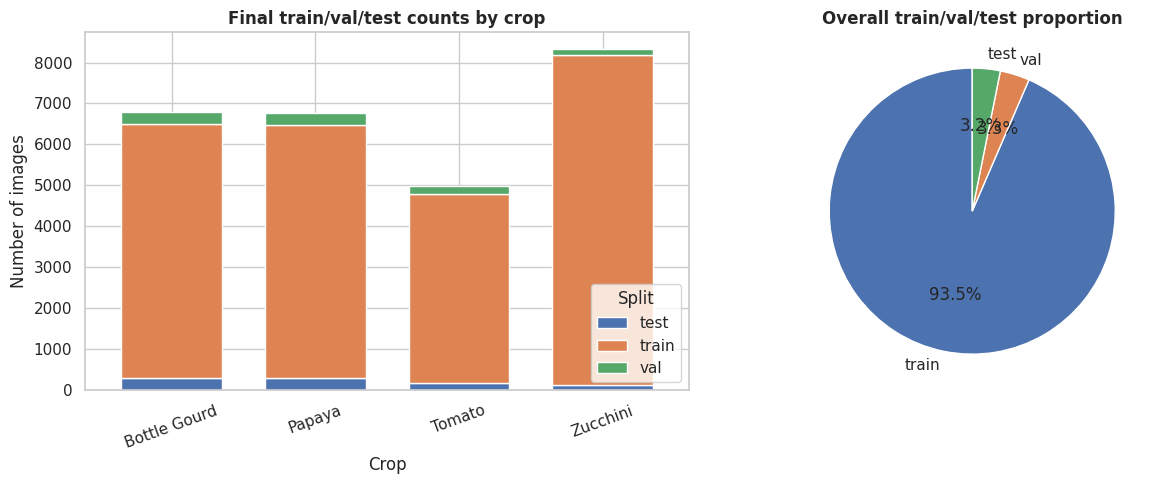


Original-image split (the source of truth): {'train': 3035, 'test': 635, 'val': 634}


In [8]:
split_counts_by_crop = out.groupby(["crop", "model_split"]).size().unstack(fill_value=0)
print("Final model_split counts by crop:\n")
print(split_counts_by_crop)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

split_counts_by_crop.plot(kind="bar", stacked=True, ax=axes[0],
                           color=["#4C72B0", "#DD8452", "#55A868"], width=0.7)
axes[0].set_title("Final train/val/test counts by crop")
axes[0].set_xlabel("Crop"); axes[0].set_ylabel("Number of images")
axes[0].legend(title="Split")
axes[0].tick_params(axis="x", rotation=20)

overall_counts = out["model_split"].value_counts().reindex(["train", "val", "test"])
axes[1].pie(overall_counts.values, labels=overall_counts.index, autopct="%1.1f%%",
            colors=["#4C72B0", "#DD8452", "#55A868"], startangle=90)
axes[1].set_title("Overall train/val/test proportion")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_split_composition.png", bbox_inches="tight")
plt.show()

print(f"\nOriginal-image split (the source of truth): "
      f"{out[out['split']=='Original']['model_split'].value_counts().to_dict()}")


## 3. Preprocessing — Per-Image Feature Extraction

Every `leaf_image` graph node needs a fixed-length input feature vector.
This file uses **DINOv2 ViT-B/14** as the image backbone. The pretrained
network is partially fine-tuned on the leakage-safe **train split only** with
a temporary disease-classification head, for a maximum of **400 epochs** and
early-stopping patience of **20 epochs**. The best validation-accuracy
checkpoint is restored before the temporary head is removed and a
768-dimensional feature bank is extracted for every image.

`feature = DINOv2 ViT-B/14(image) ∈ R^768`

The rest of the notebook is intentionally unchanged: graph construction, the
within-crop cosine k-NN `similar_to` edges, HGT training, the feature-only
baseline, and evaluation all consume this fixed-width feature bank without
assuming a particular backbone architecture.

**Leakage rule enforced here:** normalization statistics are fitted on the
**train split only** and then applied to validation/test. Fine-tuning also uses
only train labels and validation labels for early stopping; test labels never
influence feature learning or checkpoint selection.

A separate mean RGB brightness statistic is computed directly from raw pixels
only for the diagnostic plot below. It is not part of the model input.

### 3.1 Feature extraction with a fine-tuned DINOv2 ViT-B/14

In [9]:
import gc
import random
import torch
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image, ImageStat
import numpy as np

out = out.reset_index(drop=True)

# ---------------------------------------------------------------------------
# BACKBONE-ONLY CHANGE: the leakage-safe split, feature scaling, k-NN graph,
# heterogeneous graph schema, HGT architecture, decoder, baseline, and all
# evaluation cells remain unchanged. Only the image feature extractor is
# replaced with the official DINOv2 ViT-B/14 backbone.
#
# Kaggle note: Internet must be enabled the first time this cell downloads
# the official facebookresearch/dinov2 repository and pretrained weights.
# ---------------------------------------------------------------------------

BACKBONE_NAME = "DINOv2 ViT-B/14"
BACKBONE_FEATURE_DIM = 768
FINETUNE_EPOCHS = 400
FINETUNE_PATIENCE = 20
FINETUNE_MIN_DELTA = 1e-4
DINO_UNFROZEN_BLOCKS = 2

_finetune_diseases = sorted(out["class_name"].unique())
_finetune_class_to_id = {c: i for i, c in enumerate(_finetune_diseases)}
_finetune_labels_all = out["class_name"].map(_finetune_class_to_id).to_numpy()


class DINOv2Classifier(torch.nn.Module):
    """Temporary supervised head used only during backbone fine-tuning."""
    def __init__(self, backbone, n_classes):
        super().__init__()
        self.backbone = backbone
        feature_dim = int(getattr(backbone, "embed_dim", BACKBONE_FEATURE_DIM))
        self.classifier = torch.nn.Linear(feature_dim, n_classes)

    def forward(self, images):
        features = self.backbone(images)
        return self.classifier(features)


def build_finetune_model():
    backbone = torch.hub.load(
        "facebookresearch/dinov2", "dinov2_vitb14",
        pretrained=True, trust_repo=True, force_reload=False)

    # Freeze the full pretrained transformer, then unfreeze only the final
    # two transformer blocks and final LayerNorm. This keeps Kaggle memory
    # use manageable while allowing domain adaptation to leaf diseases.
    for parameter in backbone.parameters():
        parameter.requires_grad = False
    for block in backbone.blocks[-DINO_UNFROZEN_BLOCKS:]:
        for parameter in block.parameters():
            parameter.requires_grad = True
    for parameter in backbone.norm.parameters():
        parameter.requires_grad = True

    return DINOv2Classifier(backbone, len(_finetune_diseases)).to(DEVICE)


# 224 is divisible by the ViT-B/14 patch size and keeps T4 memory practical.
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

finetune_train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

class LeafImageDataset(Dataset):
    """
    Returns (transformed_tensor, mean_rgb_brightness) per image.
    The brightness value is computed straight from the raw pixels
    (before model normalization) and is used only for the Section 3.1
    diagnostic plots -- it is NOT part of the model's feature vector.
    """
    def __init__(self, file_paths, transform=None):
        self.file_paths = file_paths
        self.transform = transform

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, idx):
        path = self.file_paths[idx]
        try:
            with Image.open(path) as img:
                img = img.convert("RGB")
                brightness = float(np.mean(ImageStat.Stat(img).mean))
                img_t = self.transform(img) if self.transform else img
                return img_t, brightness
        except Exception:
            return torch.zeros((3, 224, 224)), float("nan")


class LeafImageLabeledDataset(Dataset):
    """Same loading logic, but returns (image, label) for supervised fine-tuning."""
    def __init__(self, file_paths, labels, transform=None):
        self.file_paths = file_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, idx):
        path = self.file_paths[idx]
        try:
            with Image.open(path) as img:
                img = img.convert("RGB")
                img_t = self.transform(img) if self.transform else img
        except Exception:
            img_t = torch.zeros((3, 224, 224))
        return img_t, int(self.labels[idx])


def run_finetune_epoch(loader, model, optimizer, criterion, device, train=True):
    set_finetune_mode(model, train)
    total_loss, n_correct, n_seen = 0.0, 0, 0
    context = torch.enable_grad() if train else torch.no_grad()
    with context:
        for imgs, lbls in loader:
            imgs, lbls = imgs.to(device, non_blocking=True), lbls.to(device, non_blocking=True)
            if train:
                optimizer.zero_grad(set_to_none=True)
            logits = model(imgs)
            loss = criterion(logits, lbls)
            if train:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(
                    [p for p in model.parameters() if p.requires_grad], 1.0)
                optimizer.step()
            total_loss += loss.item() * imgs.size(0)
            n_correct += (logits.argmax(dim=-1) == lbls).sum().item()
            n_seen += imgs.size(0)
    return total_loss / max(1, n_seen), n_correct / max(1, n_seen)


def _seed_worker(worker_id):
    np.random.seed(RNG_SEED + worker_id)
    random.seed(RNG_SEED + worker_id)


def build_finetune_loaders(batch_size):
    generator = torch.Generator()
    generator.manual_seed(RNG_SEED)
    train_rows = out[out["model_split"] == "train"]
    val_rows = out[out["model_split"] == "val"]
    train_ds = LeafImageLabeledDataset(
        train_rows["path"].tolist(),
        _finetune_labels_all[train_rows.index.to_numpy()],
        transform=finetune_train_transform)
    val_ds = LeafImageLabeledDataset(
        val_rows["path"].tolist(),
        _finetune_labels_all[val_rows.index.to_numpy()],
        transform=transform)
    train_loader = DataLoader(
        train_ds, batch_size=batch_size, shuffle=True, num_workers=2,
        pin_memory=(DEVICE.type == "cuda"), generator=generator,
        worker_init_fn=_seed_worker)
    val_loader = DataLoader(
        val_ds, batch_size=batch_size, shuffle=False, num_workers=2,
        pin_memory=(DEVICE.type == "cuda"))
    return train_loader, val_loader


def set_finetune_mode(model, train):
    """Keep frozen transformer blocks deterministic during partial tuning."""
    model.eval()
    if train:
        for block in model.backbone.blocks[-DINO_UNFROZEN_BLOCKS:]:
            block.train()
        model.backbone.norm.train()
        model.classifier.train()


finetune_batch_size = 32
finetune_optimizer = None
best_val_acc_ft, best_backbone_state = -1.0, None
stopped_early_at_ft = None
fallback_to_pretrained = False

print(f"Fine-tuning the final {DINO_UNFROZEN_BLOCKS} blocks of {BACKBONE_NAME} on "
      f"{len(_finetune_diseases)} disease classes for up to {FINETUNE_EPOCHS} epochs "
      f"(early stopping patience={FINETUNE_PATIENCE})...")

while True:
    finetune_model = build_finetune_model()  # clean restart for every OOM retry
    try:
        train_loader_ft, val_loader_ft = build_finetune_loaders(finetune_batch_size)
        finetune_optimizer = torch.optim.AdamW(
            [p for p in finetune_model.parameters() if p.requires_grad],
            lr=5e-5, weight_decay=1e-4)
        finetune_criterion = torch.nn.CrossEntropyLoss()

        best_val_acc_ft, best_backbone_state = -1.0, None
        epochs_no_improve_ft = 0
        stopped_early_at_ft = None

        for ft_epoch in range(1, FINETUNE_EPOCHS + 1):
            tr_loss, tr_acc = run_finetune_epoch(
                train_loader_ft, finetune_model, finetune_optimizer,
                finetune_criterion, DEVICE, train=True)
            val_loss, val_acc = run_finetune_epoch(
                val_loader_ft, finetune_model, finetune_optimizer,
                finetune_criterion, DEVICE, train=False)

            print(f"  [finetune] epoch {ft_epoch}/{FINETUNE_EPOCHS} | "
                  f"train_loss {tr_loss:.4f} train_acc {tr_acc:.4f} | "
                  f"val_loss {val_loss:.4f} val_acc {val_acc:.4f} "
                  f"(batch_size={finetune_batch_size})")

            if val_acc > best_val_acc_ft + FINETUNE_MIN_DELTA:
                best_val_acc_ft = val_acc
                best_backbone_state = {
                    key: value.detach().cpu().clone()
                    for key, value in finetune_model.state_dict().items()
                }
                epochs_no_improve_ft = 0
            else:
                epochs_no_improve_ft += 1

            if epochs_no_improve_ft >= FINETUNE_PATIENCE:
                stopped_early_at_ft = ft_epoch
                print(f"  [finetune] early stopping at epoch {ft_epoch}/{FINETUNE_EPOCHS} "
                      f"after {FINETUNE_PATIENCE} epochs without sufficient val_acc improvement. "
                      f"best_val_acc={best_val_acc_ft:.4f}")
                break

        if stopped_early_at_ft is None:
            print(f"  [finetune] completed all {FINETUNE_EPOCHS} epochs. "
                  f"best_val_acc={best_val_acc_ft:.4f}")
        break

    except torch.cuda.OutOfMemoryError as error:
        del finetune_model
        if finetune_optimizer is not None:
            del finetune_optimizer
            finetune_optimizer = None
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        if finetune_batch_size <= 4:
            print(f"Fine-tuning OOM even at batch_size={finetune_batch_size}: {error}\n"
                  "Using the untouched pretrained DINOv2 backbone for feature extraction.")
            fallback_to_pretrained = True
            break
        finetune_batch_size = max(4, finetune_batch_size // 2)
        print(f"Fine-tuning OOM -- restarting with batch_size={finetune_batch_size}...")

if fallback_to_pretrained:
    finetune_model = build_finetune_model()
elif best_backbone_state is not None:
    finetune_model.load_state_dict(best_backbone_state)
    print(f"Loaded best fine-tuned {BACKBONE_NAME} checkpoint "
          f"(val_acc={best_val_acc_ft:.4f}).")

# Discard the temporary classifier and retain only the 768-dim DINOv2 encoder.
cnn_backbone = finetune_model.backbone
cnn_backbone.eval()
del finetune_model

print(f"Extracting {BACKBONE_NAME} features for {len(out):,} images...")


def extract_features(batch_size):
    img_dataset = LeafImageDataset(out["path"].tolist(), transform=transform)
    img_loader = DataLoader(
        img_dataset, batch_size=batch_size, shuffle=False, num_workers=2,
        pin_memory=(DEVICE.type == "cuda"))
    feats, brightness = [], []
    with torch.no_grad():
        for batch_imgs, batch_brightness in img_loader:
            batch_imgs = batch_imgs.to(DEVICE, non_blocking=True)
            out_feats = cnn_backbone(batch_imgs).cpu().numpy()
            feats.append(out_feats)
            brightness.append(batch_brightness.numpy())
    return (np.concatenate(feats, axis=0).astype(np.float32),
            np.concatenate(brightness, axis=0))


extract_batch_size = 64
while True:
    try:
        raw_feats, mean_brightness = extract_features(extract_batch_size)
        break
    except torch.cuda.OutOfMemoryError as error:
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        if extract_batch_size <= 4:
            raise RuntimeError(
                f"Feature extraction OOM even at batch_size={extract_batch_size}") from error
        extract_batch_size = max(4, extract_batch_size // 2)
        print(f"Feature extraction OOM -- retrying with batch_size={extract_batch_size}...")

if raw_feats.shape[1] != BACKBONE_FEATURE_DIM:
    raise RuntimeError(
        f"Expected {BACKBONE_FEATURE_DIM} features from {BACKBONE_NAME}, "
        f"but received {raw_feats.shape[1]}.")
print(f"New feature matrix shape: {raw_feats.shape}")

# The backbone is no longer needed after the one-time feature-bank extraction.
del cnn_backbone
if finetune_optimizer is not None:
    del finetune_optimizer
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Train-only standardization: the leakage rule remains unchanged.
train_mask = (out["model_split"] == "train").to_numpy()
feat_mean = raw_feats[train_mask].mean(axis=0)
feat_std = raw_feats[train_mask].std(axis=0)
feat_std[feat_std < 1e-8] = 1.0
scaled_feats = ((raw_feats - feat_mean) / feat_std).astype(np.float32)
print("Scaled feature matrix shape:", scaled_feats.shape)


Fine-tuning the final 2 blocks of DINOv2 ViT-B/14 on 28 disease classes for up to 400 epochs (early stopping patience=20)...
Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip
Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vitb14/dinov2_vitb14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vitb14_pretrain.pth


100%|██████████| 330M/330M [00:00<00:00, 348MB/s]


  [finetune] epoch 1/400 | train_loss 0.9259 train_acc 0.6502 | val_loss 0.5931 val_acc 0.7634 (batch_size=32)
  [finetune] epoch 2/400 | train_loss 0.5564 train_acc 0.7688 | val_loss 0.4300 val_acc 0.8426 (batch_size=32)
  [finetune] epoch 3/400 | train_loss 0.4348 train_acc 0.8117 | val_loss 0.3137 val_acc 0.8806 (batch_size=32)
  [finetune] epoch 4/400 | train_loss 0.3715 train_acc 0.8326 | val_loss 0.3239 val_acc 0.8884 (batch_size=32)
  [finetune] epoch 5/400 | train_loss 0.3396 train_acc 0.8467 | val_loss 0.2903 val_acc 0.8973 (batch_size=32)
  [finetune] epoch 6/400 | train_loss 0.3191 train_acc 0.8522 | val_loss 0.3165 val_acc 0.9040 (batch_size=32)
  [finetune] epoch 7/400 | train_loss 0.2980 train_acc 0.8610 | val_loss 0.3641 val_acc 0.8917 (batch_size=32)
  [finetune] epoch 8/400 | train_loss 0.2882 train_acc 0.8632 | val_loss 0.2830 val_acc 0.9051 (batch_size=32)
  [finetune] epoch 9/400 | train_loss 0.2751 train_acc 0.8696 | val_loss 0.2618 val_acc 0.9096 (batch_size=32)
 

### 3.2 Feature distribution sanity checks

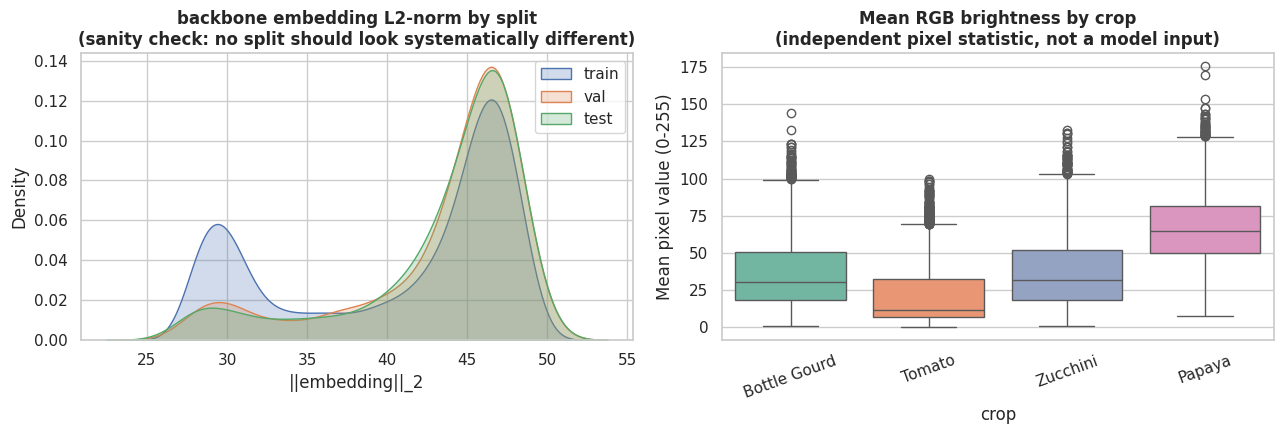

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

embedding_norms = np.linalg.norm(raw_feats, axis=1)
for split, color in zip(["train", "val", "test"], ["#4C72B0", "#DD8452", "#55A868"]):
    mask = (out["model_split"] == split).to_numpy()
    sns.kdeplot(embedding_norms[mask], ax=axes[0], label=split, fill=True, alpha=0.25, color=color)
axes[0].set_title("backbone embedding L2-norm by split\n(sanity check: no split should look systematically different)")
axes[0].set_xlabel("||embedding||_2")
axes[0].legend()

sns.boxplot(x=out["crop"], y=mean_brightness, ax=axes[1], palette="Set2")
axes[1].set_title("Mean RGB brightness by crop\n(independent pixel statistic, not a model input)")
axes[1].set_ylabel("Mean pixel value (0-255)")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_feature_distributions.png", bbox_inches="tight")
plt.show()

## 4. Building the Multi-Crop Disease Relational Graph

This is what makes the model **relational** rather than a per-crop image
classifier: every leaf image is one node in a heterogeneous graph that also
contains **crop** nodes, **disease** nodes, and coarse **disease-category**
nodes, connected so that biologically/visually related conditions — even
across *different crops* — share graph structure.

**Node types (4):**
| Node type | Count (this run) | What it represents |
|---|---|---|
| `leaf_image` | one per image | a single photographed leaf |
| `crop` | 4 | Bottle Gourd / Papaya / Tomato / Zucchini |
| `disease` | 28 | each crop-qualified class, e.g. `Tomato_Spot`, `Papaya_Mosaic_Virus` — the exact class names the EDA discovered |
| `disease_category` | ≤7 | coarse cross-crop grouping: Viral / Fungal / Bacterial / Pest / Nutrient_Deficiency / Healthy / Other, assigned by keyword-matching the disease name |

**Edges** (pyHGT's `Graph.add_edge(..., directed=True)` auto-creates the
reverse relation for each of these, so the true edge-type count is double
this list) — matching the hand-drawn schema this notebook follows:
- `leaf_image → disease` (`has_disease`)
- `disease → disease_category` (`is_type_of`)
- `leaf_image → crop` (`grown_on`)
- `crop → disease` (`affects`)
- `leaf_image → leaf_image` (`similar_to`, k-NN in backbone feature space — see Section 4.2)

Note there is **no `leaf_image → disease` edge** in the message-passing
graph, for train, val, *or* test images. An earlier version of this
notebook added that edge for train images only (reasoning: "the class
folder an image came from is always known, so it's not leakage"). That
reasoning about *label leakage* was correct, but it missed a *structural*
problem: with a 2-layer GNN, a train leaf node connected to its own
disease node gets a 2-hop path back to itself (`leaf → disease → leaf`),
so its final representation is partly reconstructed from a node built out
of itself and its same-class peers — an easy shortcut with no equivalent
at val/test time, since those nodes never had that edge. The model learned
to exploit exactly that shortcut (train loss → ~0, val accuracy stuck far
below a plain linear-probe baseline on the same features) rather than
learning generalizable structure. Removing the edge for every split makes
every `leaf_image` node's neighborhood shape identical regardless of split,
so whatever the GNN learns from train nodes actually transfers.

Classification still happens through the relational graph: each leaf's
final embedding (built from its `crop` neighborhood *and* its `similar_to`
k-NN leaf neighborhood, Section 4.2) is scored against the `disease` node
embeddings (which get their structure purely from `affects`/`is_type_of`
edges to `crop`/`disease_category`) via the bilinear predictor below —
cross-crop biologically-related diseases (e.g. `Tomato_Mosaic` and
`Papaya_Mosaic_Virus`, both under `Viral`) still share statistical strength
through the `disease_category` node, without any node ever seeing a
training label as a graph edge.

### 4.1 Node types, disease categorization, and the message/supervision split

In [11]:
def categorize_disease(class_name: str) -> str:
    name = class_name.lower()

    if "healthy" in name:
        return "Healthy"

    if "mosaic" in name or "virus" in name:
        return "Viral"

    if "bacterial" in name or "xanthomonas" in name:
        return "Bacterial"

    if any(k in name for k in [
        "blight", "mildew", "midew", "anthracnose",
        "fungal", "necrotic", "downy"
    ]):
        return "Fungal"

    # Must be checked before the general word "damage"
    if "chlorosis" in name or "iron" in name:
        return "Nutrient_Deficiency"

    if any(k in name for k in [
        "insect", "hole", "damage", "carica"
    ]):
        return "Pest"

    return "Other"


def make_msg_sup_split(df_with_split, seed=RNG_SEED, msg_frac=0.75):
    """
    FIX (v4, replaces the v2 "remove has_disease entirely" approach):

    v2 removed every has_disease edge, including for train, because a naive
    train-only edge gave train leaf nodes a 2-hop shortcut (leaf -> disease
    -> leaf) that val/test could never structurally have -- that mismatch
    (not overfitting) is what collapsed HGT to 16.3% test accuracy, below
    the no-graph baseline. But removing the edges entirely also removed all
    real visual grounding for disease nodes: two diseases sharing a crop and
    a disease_category become structurally identical, and only the
    MetaNodeEmbedding's learned-but-arbitrary vector separates them.

    This is the proper fix: a permanent, disjoint message-passing /
    supervision split of the TRAIN rows only (stratified per class so every
    disease still gets real grounding):
      - train_msg : keeps its has_disease edge forever. Never scored in the
        loss (its own prediction would be a trivial shortcut), but its real
        backbone features flow into the disease node via message passing.
      - train_sup : NEVER gets a has_disease edge -- structurally identical
        to val/test rows, and this is the ONLY set the training loss uses.

    Because the split is fixed (not re-drawn per epoch or per forward pass),
    train_sup rows have an unchanging structural view that exactly matches
    val/test, so the shortcut that broke v2 can't reappear -- while disease
    nodes still get real aggregated visual signal from train_msg rows,
    which v2 gave up entirely.
    """
    # FIX (v5): group by near-duplicate identity BEFORE assigning roles.
    # matched_original_idx (set by link_augmented_to_originals in the
    # leakage-safe split) tells us which Original each Augmented image is a
    # near-duplicate of. Without this grouping, an Original could land in
    # train_msg while its own Augmented derivative lands in train_sup --
    # that derivative's supervised loss would then be scored against a
    # disease node that already saw a near-pixel-identical image via message
    # passing, reopening the exact shortcut this split exists to close, one
    # level down inside train. Grouping keeps every Original + its matched
    # Augmented copies on the same side of the split, always.
    rng = np.random.RandomState(seed)
    role = pd.Series("none", index=df_with_split.index)
    train_idx = df_with_split.index[df_with_split["model_split"] == "train"]
    train_df = df_with_split.loc[train_idx]

    if "matched_original_idx" in train_df.columns:
        own_idx = pd.Series(train_df.index, index=train_df.index)
        group_key = train_df["matched_original_idx"].fillna(own_idx)
    else:
        group_key = pd.Series(train_df.index, index=train_df.index)

    for cls, grp in train_df.groupby("class_name"):
        gkeys = group_key.loc[grp.index]
        unique_groups = gkeys.unique()
        rng.shuffle(unique_groups)
        n_msg_groups = max(1, int(round(len(unique_groups) * msg_frac)))
        msg_groups = set(unique_groups[:n_msg_groups])
        assigned = gkeys.map(lambda g: "train_msg" if g in msg_groups else "train_sup")
        role.loc[grp.index] = assigned
    return role


def build_graph(df_with_split, image_features, msg_role):
    """
    Build the heterogeneous graph.

    msg_role : pandas Series aligned with df_with_split rows, values in
        {"train_msg", "train_sup", "none"} (val/test rows are "none").
        Only "train_msg" rows get a `has_disease` edge to their true disease
        node -- this is the message-passing / supervision split (see
        make_msg_sup_split above). "train_sup", val, and test rows never
        get this edge, so they share an identical structural view.
    """
    graph = Graph()  # genuine pyHGT.data.Graph
    d = df_with_split.reset_index(drop=True)
    assert len(d) == len(image_features)
    msg_role = msg_role.reset_index(drop=True)
    assert len(msg_role) == len(d)

    crops = sorted(d["crop"].unique())
    diseases = sorted(d["class_name"].unique())
    categories = sorted({categorize_disease(x) for x in diseases})

    for crop in crops:
        graph.add_node({"id": f"crop::{crop}", "type": "crop"})
    for disease in diseases:
        graph.add_node({"id": f"disease::{disease}", "type": "disease"})
    for cat in categories:
        graph.add_node({"id": f"category::{cat}", "type": "disease_category"})

    leaf_image_ids = []
    n_disease_edges_added, n_disease_edges_skipped = 0, 0
    for i, row in d.iterrows():
        node_id = f"leaf_image::{i}"
        graph.add_node({"id": node_id, "type": "leaf_image"})
        leaf_image_ids.append(node_id)

        # --- FIX v4: has_disease is added ONLY for the fixed train_msg
        # subset (see make_msg_sup_split). train_sup / val / test rows never
        # get it, so the loss (computed only on train_sup) is scored on
        # exactly the same structural view as val/test -- no shortcut.
        if msg_role.iloc[i] == "train_msg":
            graph.add_edge({"id": node_id, "type": "leaf_image"},
                            {"id": f"disease::{row['class_name']}", "type": "disease"},
                            time=0, relation_type="has_disease", directed=True)
            n_disease_edges_added += 1
        else:
            n_disease_edges_skipped += 1

        # crop is legitimately known for every image regardless of split
        # (it's how the photo was filed, not what we're predicting), so this
        # edge is added for train/val/test alike.
        graph.add_edge({"id": node_id, "type": "leaf_image"},
                        {"id": f"crop::{row['crop']}", "type": "crop"},
                        time=0, relation_type="grown_on", directed=True)

    print(f"has_disease edges added (train_msg only): {n_disease_edges_added:,}")
    print(f"leaf_image rows with has_disease withheld (train_sup + val + test): {n_disease_edges_skipped:,}")

    for disease in diseases:
        crop_for_disease = d.loc[d["class_name"] == disease, "crop"].iloc[0]
        # Direction/name matches the hand-drawn schema: crop -> disease
        # ("affects"), not disease -> crop. The crop is the source node and
        # disease the target, mirroring the leaf_image -> disease
        # (has_disease) and disease -> disease_category (is_type_of) edges,
        # which all point "upward" toward the more general node.
        graph.add_edge({"id": f"crop::{crop_for_disease}", "type": "crop"},
                        {"id": f"disease::{disease}", "type": "disease"},
                        time=0, relation_type="affects", directed=True)
        graph.add_edge({"id": f"disease::{disease}", "type": "disease"},
                        {"id": f"category::{categorize_disease(disease)}", "type": "disease_category"},
                        time=0, relation_type="is_type_of", directed=True)

    # NEW: disease <-> disease edges between every pair of diseases that
    # share the same disease_category (e.g. Tomato_Mosaic <-> Papaya_
    # Mosaic_Virus, both "Viral"). Previously, cross-crop biologically-
    # related diseases could only reach each other via a 2-hop path through
    # the shared disease_category node; this gives them a direct 1-hop
    # message-passing channel instead, so their embeddings can share
    # statistical strength more directly. pyHGT auto-adds the reverse
    # relation, so the connection is effectively symmetric.
    from itertools import combinations
    category_members = defaultdict(list)
    for disease in diseases:
        category_members[categorize_disease(disease)].append(disease)
    n_disease_disease_edges = 0
    for cat, members in category_members.items():
        for disease_a, disease_b in combinations(sorted(members), 2):
            graph.add_edge({"id": f"disease::{disease_a}", "type": "disease"},
                            {"id": f"disease::{disease_b}", "type": "disease"},
                            time=0, relation_type="co_category", directed=True)
            n_disease_disease_edges += 1
    print(f"disease<->disease co_category edges added: {n_disease_disease_edges:,}")

    # Populate graph.node_feature so pyHGT's own Graph.get_types()/to_torch()
    # machinery works as designed: leaf_image nodes carry their real scaled
    # backbone feature vector. crop/disease/disease_category nodes get a
    # zero *placeholder* here -- they are NOT meant to stay zero. Section 6
    # (train_hgt_link_prediction / MetaNodeEmbedding) overwrites this exact
    # zero block with a learnable per-node vector on every forward pass.
    feat_dim = image_features.shape[1]
    type_feats = {t: [None] * len(graph.node_forward[t]) for t in graph.node_forward}
    for i, node_id in enumerate(leaf_image_ids):
        ser = graph.node_forward["leaf_image"][node_id]
        type_feats["leaf_image"][ser] = image_features[i]
    # match dtype to the real image features (now float32 backbone embeddings)
    # so node_feature entries are homogeneous before to_torch() builds the tensor
    zero_vec = np.zeros(feat_dim, dtype=image_features.dtype)
    for t in ["crop", "disease", "disease_category"]:
        for node_id, ser in graph.node_forward[t].items():
            type_feats[t][ser] = zero_vec
    for t in type_feats:
        graph.node_feature[t] = type_feats[t]

    return graph, leaf_image_ids, crops, diseases, categories


# --- updated call site: fixed msg/sup split replaces the old boolean train_mask ---
# CHANGE: msg_frac raised 0.6 -> 0.75. At n_layers=1, disease-node
# embeddings only get updated from leaves with a live has_disease edge,
# so routing more train rows into train_msg (at the cost of train_sup,
# the loss population) gives that single hop more real visual grounding
# to relay -- directly targeting what n_layers=1 needs most.
msg_role = make_msg_sup_split(out, seed=RNG_SEED, msg_frac=0.75)
print("msg/sup split (train rows only):")
print(msg_role[msg_role != "none"].value_counts())

graph, leaf_image_ids, crops, diseases, categories = build_graph(out, scaled_feats, msg_role)

print("\nNode types and counts:")
for t in graph.get_types():
    print(f"  {t}: {len(graph.node_feature[t]):,}")


msg/sup split (train rows only):
train_msg    18881
train_sup     6241
Name: count, dtype: int64
has_disease edges added (train_msg only): 18,881
leaf_image rows with has_disease withheld (train_sup + val + test): 7,985
disease<->disease co_category edges added: 65

Node types and counts:
  crop: 4
  disease: 28
  disease_category: 7
  leaf_image: 26,866


### 4.2 Architecture fix: give `leaf_image` nodes real, individuating neighbors

**Symptom (previous run):** after fixing the label-leakage and node-symmetry
bugs, HGT reached test accuracy 60.4% / macro-F1 0.553 -- still *worse* than
the plain logistic-regression baseline on the exact same features (70.7% /
0.609).

**Root cause:** the only edge a `leaf_image` node had was to its `crop`
node -- one of just 4 values. Thousands of images of the same crop, spanning
many different diseases, all shared that single neighbor. With attention-
based message passing, every same-crop leaf's representation got pulled
toward the same crop-level aggregate, which carries almost no information
about *which* of the ~28 diseases that particular leaf has. The graph
structure was adding homogeneous noise, not discriminative signal -- so it's
no surprise it dragged the classifier below a baseline that ignores the
graph entirely.

**Fix:** connect each `leaf_image` node to its `K` nearest neighbors in
backbone feature space (`similar_to`, cosine similarity on the already
train-fit-only-scaled embeddings). This is **not label leakage** -- it only
uses each image's own pixel-derived features, which are available for
train/val/test alike; it never touches a label. This is the standard way
transductive GNNs (e.g. citation-network GCNs) get real structure to
aggregate over. It gives every leaf genuinely individuating neighbors --
visually/texturally similar images, which correlate far more with the true
disease label than "grown in the same one of 4 crops" ever could.


In [12]:
from sklearn.neighbors import NearestNeighbors

# Number of nearest neighbors per leaf_image node. Kept modest (5) so the
# leaf-leaf subgraph stays sparse and each neighbor is a genuinely close
# match, not a distant, weakly-similar one that would reintroduce the same
# "shared with everyone" noise problem the crop-only graph had.
K_NEIGHBORS = 5

# FIX: k-NN is now computed WITHIN EACH CROP, not globally across all
# leaf_image nodes. A global k-NN search is dominated by cross-crop visual
# similarity -- leaf shape, color, and background vary far more between
# species (Tomato vs Papaya vs Zucchini vs Bottle Gourd) than between
# disease states of the same species -- so a leaf's 5 globally-nearest
# neighbors often turn out to be same-crop-but-different-disease images
# that merely share lighting or leaf silhouette, diluting the
# disease-relevant signal this edge type exists to provide. Crop identity
# is already captured by the `grown_on` edge, so the k-NN graph's job is to
# supply what that edge can't: fine-grained, disease-relevant texture
# similarity. Restricting the search to other leaves of the SAME crop
# forces every neighbor comparison to compete on that finer-grained
# texture, instead of being dominated by which of the 4 crops it is.
#
# cosine metric on the train-fit-only scaled backbone features from Section 3
# (no label information enters this computation at all).
#
# `knn_idx` keeps the same (N, K_NEIGHBORS+1) shape/convention as before
# (column 0 = the point itself) so Section 4.3's plot_partial_graph_with_knn
# still works unmodified -- rows for crops with fewer than K_NEIGHBORS+1
# members are padded with self-indices.
knn_idx = np.tile(np.arange(len(out)).reshape(-1, 1), (1, K_NEIGHBORS + 1))

n_knn_edges = 0
for crop_name, idx in out.groupby("crop").groups.items():
    idx = np.asarray(idx)
    k_eff = min(K_NEIGHBORS, len(idx) - 1)
    if k_eff < 1:
        continue  # a crop with only 1 image has no possible neighbor
    crop_feats = scaled_feats[idx]
    nbrs = NearestNeighbors(n_neighbors=k_eff + 1, metric="cosine", n_jobs=-1).fit(crop_feats)
    _, knn_idx_local = nbrs.kneighbors(crop_feats)
    global_neighbors = idx[knn_idx_local]  # map crop-local positions -> global row indices

    for row_pos, global_i in enumerate(idx):
        neighbors = global_neighbors[row_pos]
        knn_idx[global_i, :len(neighbors)] = neighbors
        src_id = leaf_image_ids[global_i]
        for dst_global in neighbors[1:]:  # column 0 is always the point itself -- skip it
            dst_id = leaf_image_ids[int(dst_global)]
            graph.add_edge({"id": src_id, "type": "leaf_image"},
                            {"id": dst_id, "type": "leaf_image"},
                            time=0, relation_type="similar_to", directed=True)
            n_knn_edges += 1

print(f"similar_to (k-NN, k={K_NEIGHBORS}, computed WITHIN each crop) leaf-leaf edges added: {n_knn_edges:,}")
print("(pyHGT auto-adds the reverse 'rev_similar_to' relation for message passing both ways.)")


similar_to (k-NN, k=5, computed WITHIN each crop) leaf-leaf edges added: 134,330
(pyHGT auto-adds the reverse 'rev_similar_to' relation for message passing both ways.)


### 4.3 Graph schema diagram

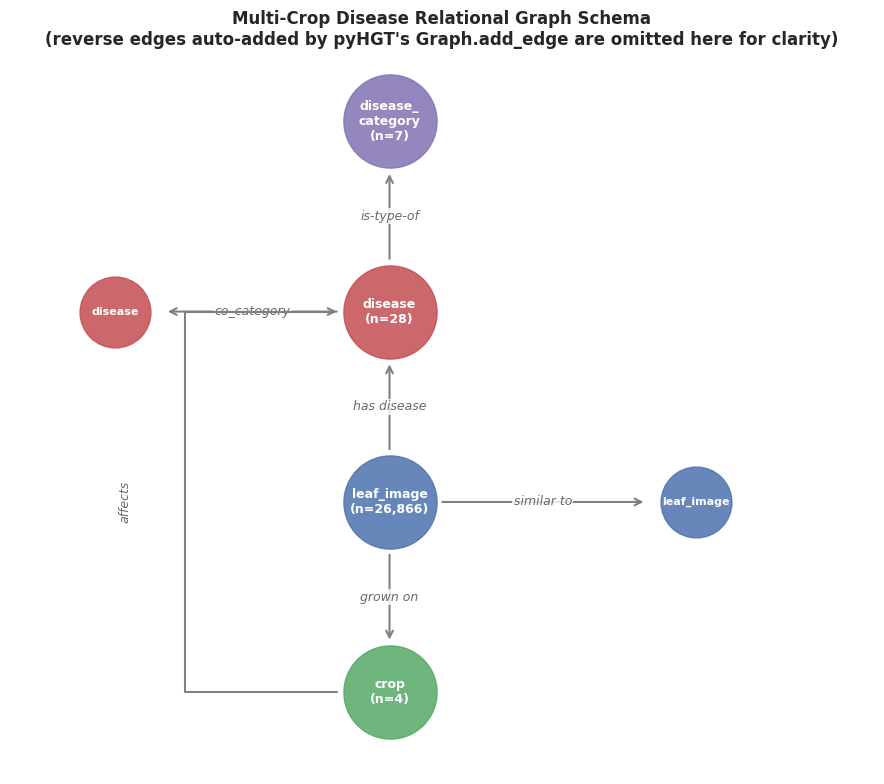

In [13]:
fig, ax = plt.subplots(figsize=(9, 8))
ax.axis("off")

# Layout mirrors the hand-drawn schema this notebook follows: a single
# vertical chain (leaf_image -> disease -> disease_category) with crop
# hanging below leaf_image, a "similar_to" leaf-image duplicate off to the
# side, and a long crop -> disease ("affects") connector routed around the
# left, exactly as sketched.
positions = {
    "disease_category": (0.42, 0.90),
    "disease":           (0.42, 0.62),
    "disease_sim":       (0.08, 0.62),   # duplicate node just for the co_category edge
    "leaf_image":        (0.42, 0.34),
    "leaf_image_sim":    (0.80, 0.34),   # duplicate node just for the similar_to edge
    "crop":              (0.42, 0.06),
}
colors = {"leaf_image": "#4C72B0", "leaf_image_sim": "#4C72B0", "disease": "#C44E52",
          "disease_sim": "#C44E52", "crop": "#55A868", "disease_category": "#8172B2"}
labels = {
    "leaf_image":        f"leaf_image\n(n={len(graph.node_forward['leaf_image']):,})",
    "leaf_image_sim":    "leaf_image",
    "disease":           f"disease\n(n={len(graph.node_forward['disease'])})",
    "disease_sim":       "disease",
    "crop":              f"crop\n(n={len(graph.node_forward['crop'])})",
    "disease_category":  f"disease_\ncategory\n(n={len(graph.node_forward['disease_category'])})",
}

# Straight, "upward-chain" edges: leaf_image -> disease -> disease_category,
# plus leaf_image -> crop (downward) and leaf_image -> leaf_image_sim (sideways).
straight_edges = [
    ("leaf_image", "disease", "has disease"),
    ("disease", "disease_category", "is-type-of"),
    ("leaf_image", "crop", "grown on"),
    ("leaf_image", "leaf_image_sim", "similar to"),
    ("disease", "disease_sim", "co_category"),
]
for a, b, label in straight_edges:
    xa, ya = positions[a]; xb, yb = positions[b]
    ax.annotate("", xy=(xb, yb), xytext=(xa, ya),
                arrowprops=dict(arrowstyle="->", color="gray", lw=1.5,
                                 shrinkA=38, shrinkB=38))
    ax.text((xa + xb) / 2, (ya + yb) / 2, label, fontsize=9, ha="center", va="center",
            style="italic", color="dimgray",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1))

# crop -> disease ("affects"), routed as a box/bracket around the left side,
# matching the hand-drawn sketch (rather than a straight diagonal line).
xa, ya = positions["crop"]
xb, yb = positions["disease"]
bracket_x = xa - 0.30
ax.annotate("", xy=(xb, yb), xytext=(xa, ya),
            arrowprops=dict(arrowstyle="->", color="gray", lw=1.5,
                             shrinkA=38, shrinkB=38,
                             connectionstyle=f"bar,armA=0,armB=0,fraction={-(xa - bracket_x) / abs(yb - ya):.3f}"))
ax.text(bracket_x - 0.02, (ya + yb) / 2, "affects", fontsize=9, ha="right", va="center",
        style="italic", color="dimgray", rotation=90,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1))

_DUPLICATE_NODE_KEYS = ("leaf_image_sim", "disease_sim")
for t, (x, y) in positions.items():
    node_key = "leaf_image" if t == "leaf_image_sim" else ("disease" if t == "disease_sim" else t)
    ax.scatter([x], [y], s=4500 if t not in _DUPLICATE_NODE_KEYS else 2600,
               color=colors[t], alpha=0.85, zorder=3)
    ax.text(x, y, labels[t], fontsize=9 if t not in _DUPLICATE_NODE_KEYS else 8,
            ha="center", va="center", color="white", weight="bold", zorder=4)

ax.set_xlim(-0.05, 1.02); ax.set_ylim(-0.06, 1.0)
ax.set_title("Multi-Crop Disease Relational Graph Schema\n"
             "(reverse edges auto-added by pyHGT's Graph.add_edge are omitted here for clarity)",
             fontsize=12)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_graph_schema.png", bbox_inches="tight")
plt.show()


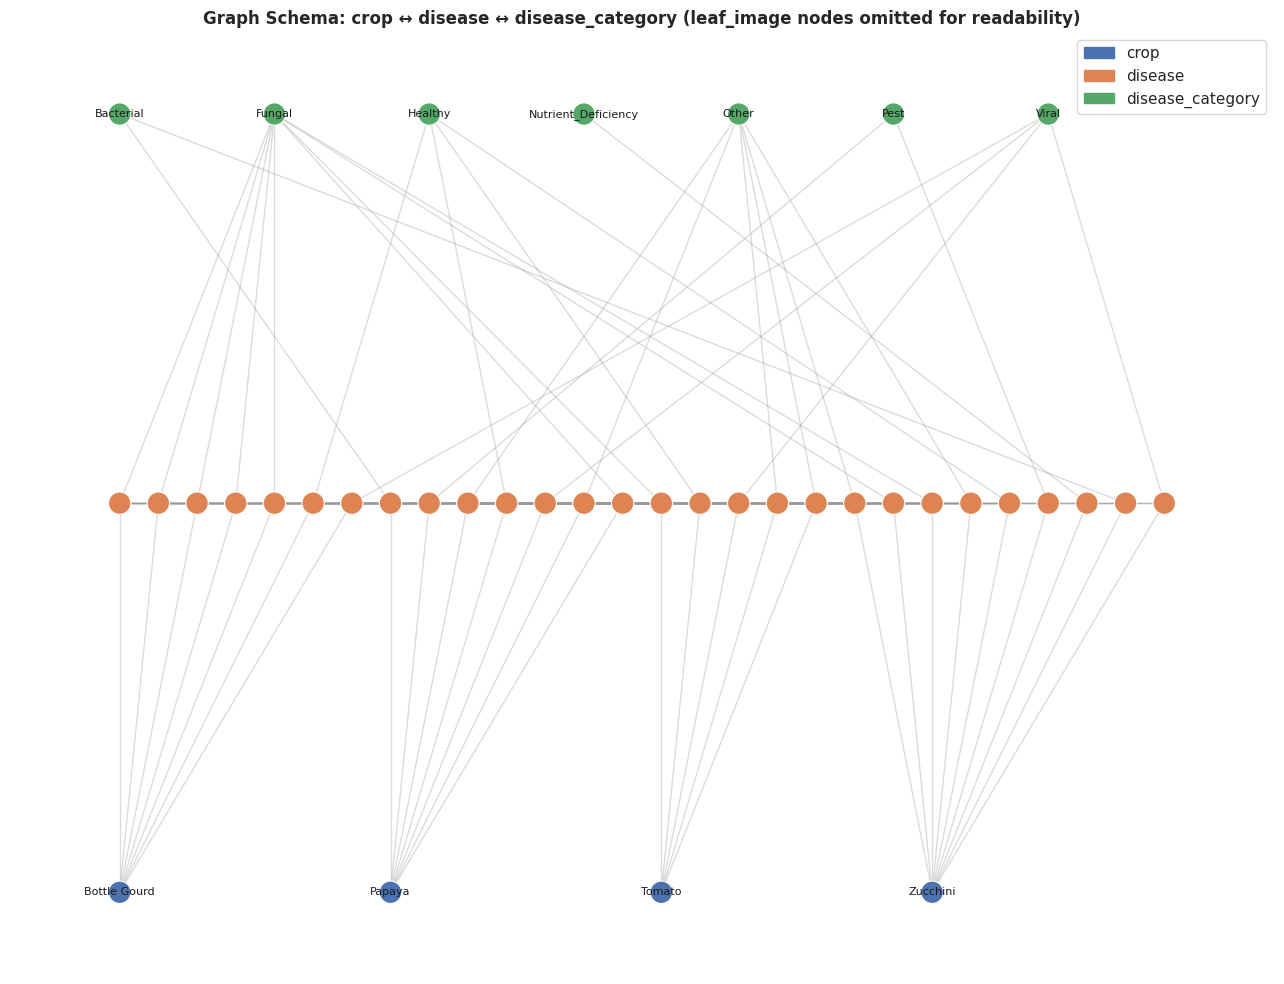

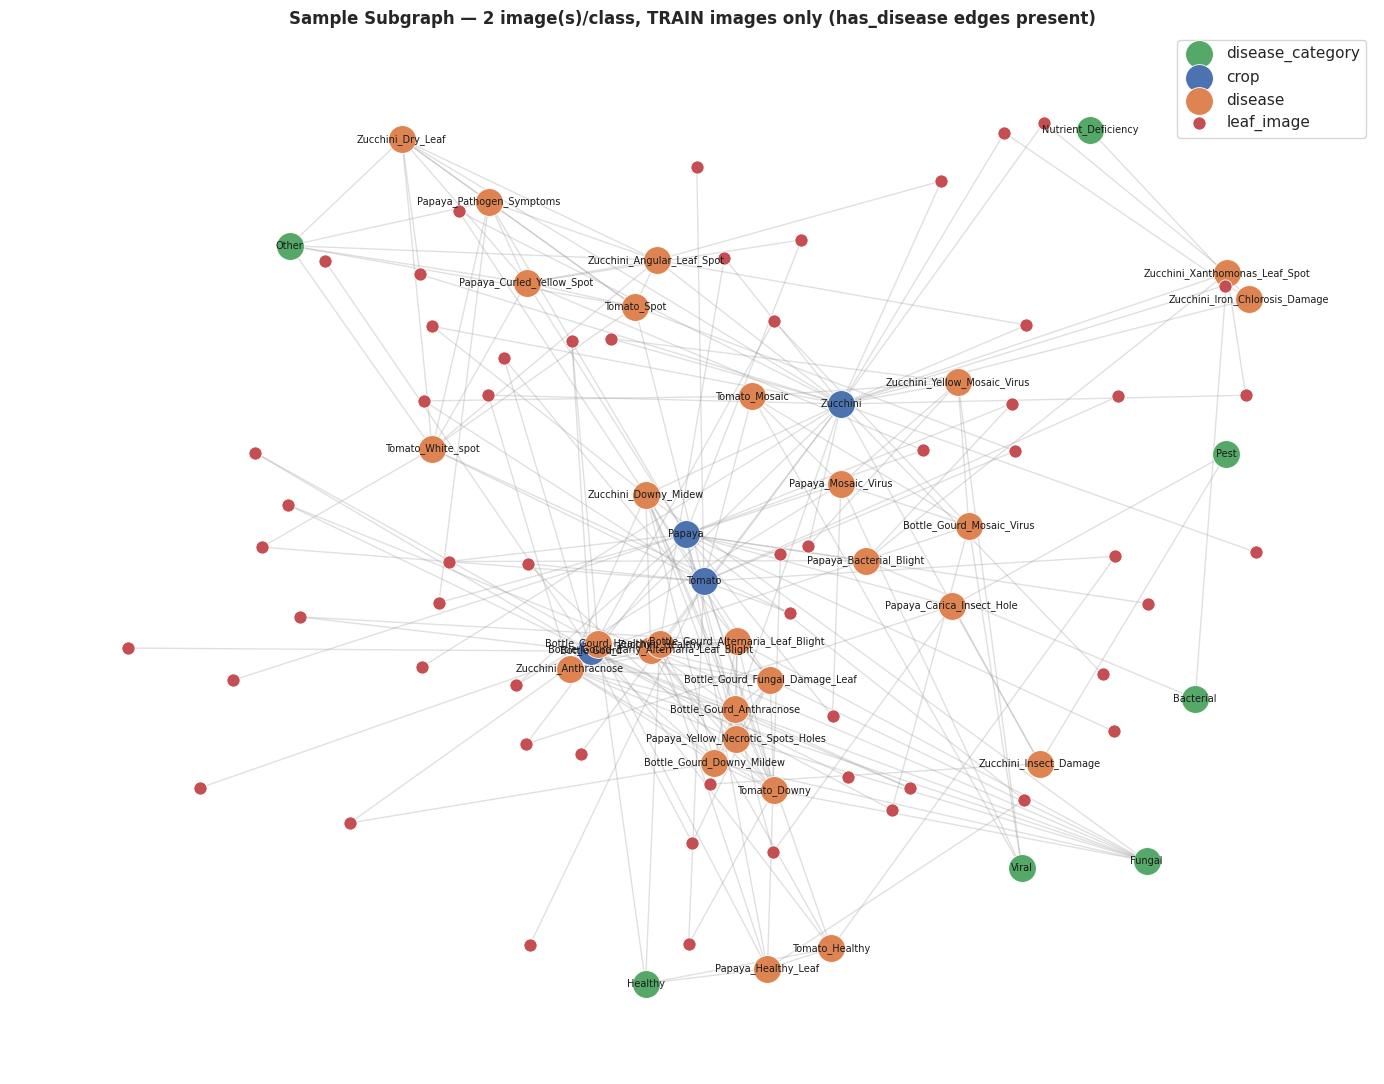

In [14]:
TYPE_COLORS = {
    "crop": "#4C72B0",
    "disease": "#DD8452",
    "disease_category": "#55A868",
    "leaf_image": "#C44E52",
}


def _pyhgt_graph_to_nx(graph, node_types=None, edge_relations=None,
                        leaf_image_subset=None):
    """
    Convert the pyHGT Graph object into a networkx.DiGraph, restricted to
    the given node types / relation types / leaf_image subset.

    leaf_image_subset : optional set of leaf_image node ids to include
        (ignored if "leaf_image" not in node_types). Use this to avoid
        trying to render tens of thousands of image nodes.
    """
    G = nx.DiGraph()
    node_types = node_types or set(graph.node_forward.keys())

    for t in node_types:
        for node_id in graph.node_forward[t]:
            if t == "leaf_image" and leaf_image_subset is not None:
                if node_id not in leaf_image_subset:
                    continue
            G.add_node(node_id, node_type=t)

    for target_type in graph.edge_list:
        if target_type not in node_types:
            continue
        for source_type in graph.edge_list[target_type]:
            if source_type not in node_types:
                continue
            for relation_type in graph.edge_list[target_type][source_type]:
                if relation_type.startswith("rev_") or relation_type == "self":
                    continue
                if edge_relations is not None and relation_type not in edge_relations:
                    continue
                rel_dict = graph.edge_list[target_type][source_type][relation_type]
                for target_ser, sources in rel_dict.items():
                    # translate int serial -> original string id
                    target_id = graph.node_bacward[target_type][target_ser]["id"]
                    if target_id not in G:
                        continue
                    for source_ser in sources:
                        source_id = graph.node_bacward[source_type][source_ser]["id"]
                        if source_id not in G:
                            continue
                        G.add_edge(source_id, target_id, relation=relation_type)
    return G


def plot_graph_schema(graph, crops, diseases, categories, figsize=(13, 10)):
    """(a) Schema view: crop / disease / disease_category nodes only."""
    G = _pyhgt_graph_to_nx(graph, node_types={"crop", "disease", "disease_category"})

    # layered layout: category on top, disease in middle, crop at bottom
    pos = {}
    for i, c in enumerate(sorted(categories)):
        pos[f"category::{c}"] = (i * (len(diseases) / max(len(categories), 1)), 2)
    for i, d in enumerate(sorted(diseases)):
        pos[f"disease::{d}"] = (i, 1)
    for i, c in enumerate(sorted(crops)):
        pos[f"crop::{c}"] = (i * (len(diseases) / max(len(crops), 1)), 0)

    fig, ax = plt.subplots(figsize=figsize)
    node_colors = [TYPE_COLORS[G.nodes[n]["node_type"]] for n in G.nodes]
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.35, arrows=False, edge_color="#999999")
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=node_colors, node_size=260,
                            edgecolors="white", linewidths=0.8)
    labels = {n: n.split("::", 1)[1] for n in G.nodes if G.nodes[n]["node_type"] != "disease"}
    nx.draw_networkx_labels(G, pos, labels=labels, ax=ax, font_size=8)

    legend_handles = [mpatches.Patch(color=col, label=t)
                       for t, col in TYPE_COLORS.items() if t != "leaf_image"]
    ax.legend(handles=legend_handles, loc="upper right")
    ax.set_title("Graph Schema: crop \u2194 disease \u2194 disease_category "
                  "(leaf_image nodes omitted for readability)")
    ax.axis("off")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "04_graph_schema.png", bbox_inches="tight")
    plt.show()


def plot_sample_subgraph(graph, out_df, leaf_image_ids, per_class=2, only_train=True,
                          seed=RNG_SEED, figsize=(14, 11)):
    """(b) Sample subgraph view: a handful of real leaf_image nodes wired in."""
    rng = np.random.RandomState(seed)
    d = out_df.reset_index(drop=True)
    pool = d[d["model_split"] == "train"] if only_train else d
    sample_rows = (pool.groupby("class_name", group_keys=False)
                        .apply(lambda g: g.sample(min(per_class, len(g)), random_state=seed)))
    sample_ids = {f"leaf_image::{i}" for i in sample_rows.index}

    G = _pyhgt_graph_to_nx(graph, node_types={"crop", "disease", "disease_category", "leaf_image"},
                            leaf_image_subset=sample_ids)

    pos = nx.spring_layout(G, seed=seed, k=0.6)
    fig, ax = plt.subplots(figsize=figsize)
    for t in ["disease_category", "crop", "disease", "leaf_image"]:
        nodelist = [n for n in G.nodes if G.nodes[n]["node_type"] == t]
        sizes = 90 if t == "leaf_image" else 400
        nx.draw_networkx_nodes(G, pos, nodelist=nodelist, node_color=TYPE_COLORS[t],
                                node_size=sizes, ax=ax, edgecolors="white", linewidths=0.6,
                                label=t)
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.3, arrows=False, edge_color="#999999")
    labels = {n: n.split("::", 1)[1] for n in G.nodes if G.nodes[n]["node_type"] != "leaf_image"}
    nx.draw_networkx_labels(G, pos, labels=labels, ax=ax, font_size=7)

    ax.legend(scatterpoints=1, loc="upper right")
    split_note = "TRAIN images only (has_disease edges present)" if only_train else \
                 "mixed split (val/test images will show NO has_disease edge \u2014 leakage fix)"
    ax.set_title(f"Sample Subgraph \u2014 {per_class} image(s)/class, {split_note}")
    ax.axis("off")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "04_graph_sample_subgraph.png", bbox_inches="tight")
    plt.show()
    return G


# --- run both views ---
plot_graph_schema(graph, crops, diseases, categories)
plot_sample_subgraph(graph, out, leaf_image_ids, per_class=2, only_train=True)

### 4.4 Partial graph view that actually contains a `similar_to` (k-NN) edge

The Section 4.2 `plot_sample_subgraph` above samples leaf images **at
random**, so the odds that any two of those random images happen to be
each other's true k-NN neighbors are astronomically low (each leaf only
has 5 specific neighbors out of ~26,866) -- in practice that plot almost
never shows a `similar_to` edge, even though `similar_to` edges are most
of the edges in the graph (134,330 of them, vs. ~57k for every other
relation type combined). This cell fixes that by deliberately seeding the
sample with a few leaf images **and their real k-NN neighbors** (pulled
from the same `knn_idx` array Section 4.2's k-NN cell computed), so the
rendered subgraph is guaranteed to show `similar_to` edges as they really
exist in the graph, not just the type-level schema.

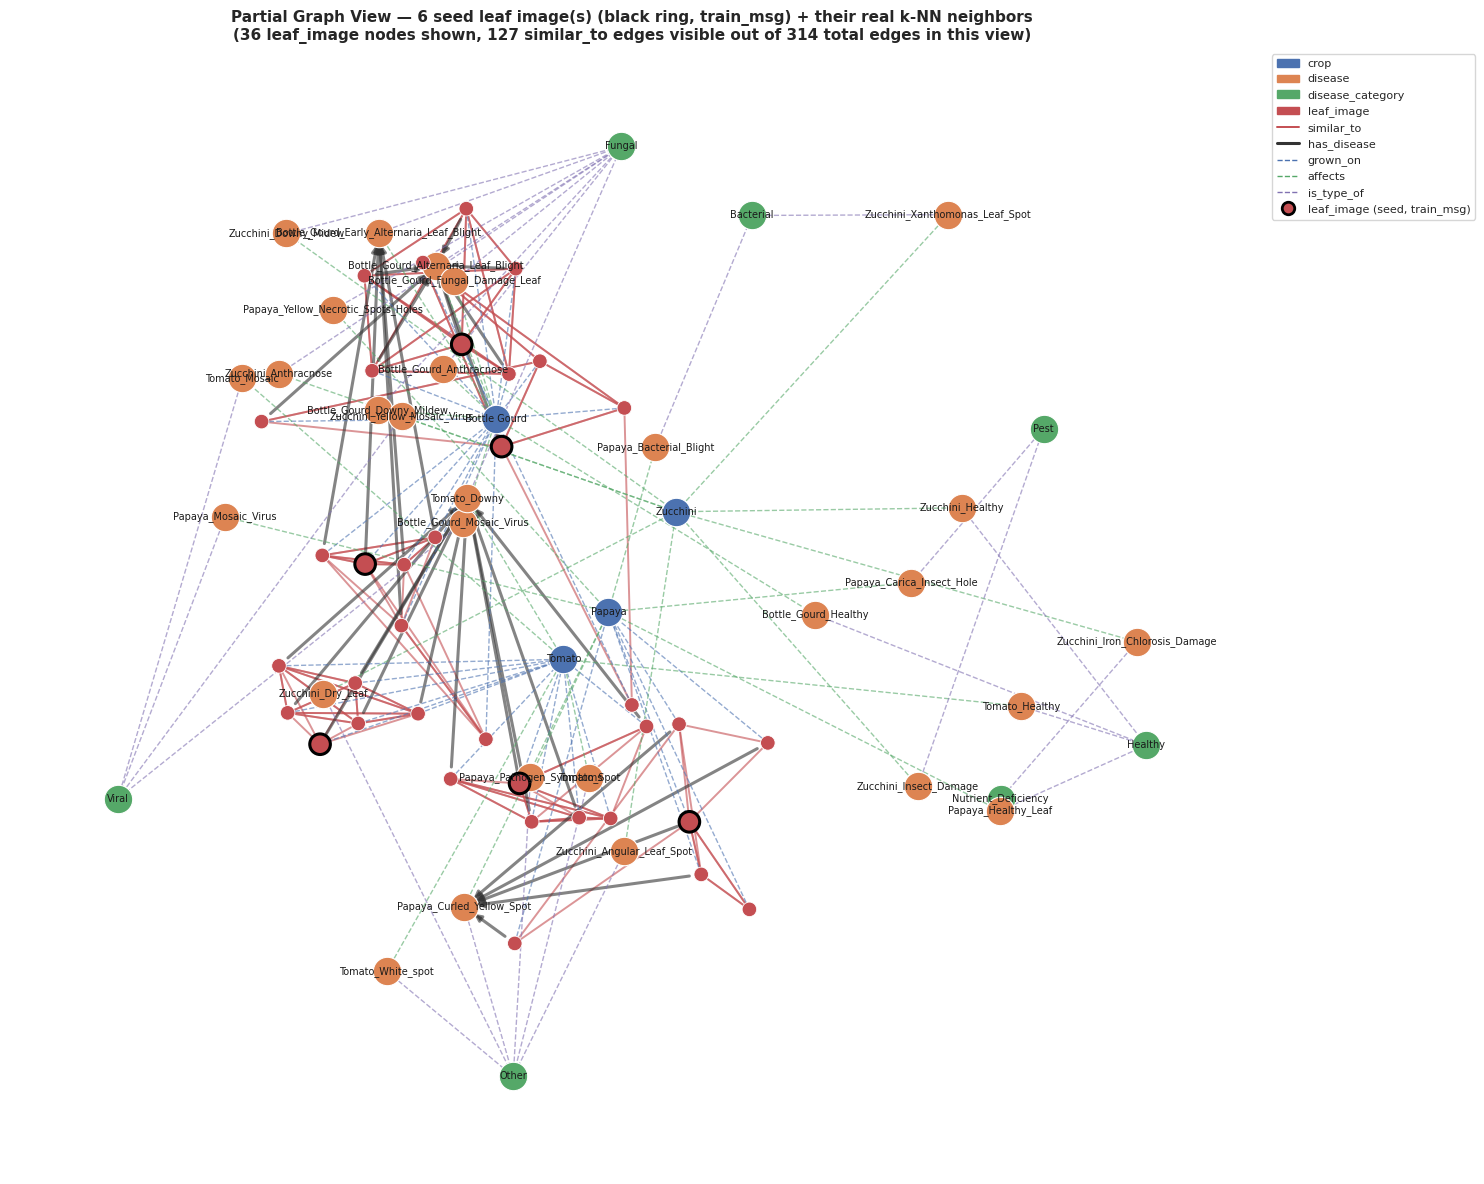

Seed leaf rows: [np.int64(549), np.int64(5689), np.int64(56), np.int64(26158), np.int64(5864), np.int64(23329)]
Total leaf_image nodes in this view: 36
Edge counts in this view by relation:
Counter({'similar_to': 127, 'co_category': 65, 'grown_on': 36, 'has_disease': 30, 'is_type_of': 28, 'affects': 28})


In [15]:
def plot_partial_graph_with_knn(graph, out_df, leaf_image_ids, knn_idx, msg_role,
                                 n_seeds=6, seed=RNG_SEED, figsize=(15, 12)):
    """
    Partial graph view built to GUARANTEE visible similar_to (k-NN) edges.

    Picks `n_seeds` leaf_image rows (preferring train_msg rows, so their
    has_disease edge is also visible), then pulls in each seed's *actual*
    k nearest neighbors (from knn_idx, the same array used to build the
    graph in Section 4.2) so the resulting node set is not a random sample
    but the real local neighborhood of each seed -- this is what makes the
    similar_to edges actually show up.
    """
    rng = np.random.RandomState(seed)
    d = out_df.reset_index(drop=True)
    role = msg_role.reset_index(drop=True)

    # prefer train_msg rows as seeds so we can also show a has_disease edge;
    # spread seeds across different crops for visual variety
    msg_rows = d.index[role == "train_msg"].to_numpy()
    rng.shuffle(msg_rows)
    seed_rows, seen_crops = [], set()
    for i in msg_rows:
        c = d.loc[i, "crop"]
        if c not in seen_crops or len(seed_rows) < n_seeds:
            seed_rows.append(i)
            seen_crops.add(c)
        if len(seed_rows) >= n_seeds:
            break

    # pull in each seed's REAL k-NN neighbors (column 0 of knn_idx is the
    # point itself, so skip it -- same convention as the graph-build cell)
    included_rows = set(seed_rows)
    for i in seed_rows:
        included_rows.update(int(j) for j in knn_idx[i, 1:])

    sample_ids = {f"leaf_image::{i}" for i in included_rows}
    seed_ids = {f"leaf_image::{i}" for i in seed_rows}

    G = _pyhgt_graph_to_nx(graph, node_types={"crop", "disease", "disease_category", "leaf_image"},
                            leaf_image_subset=sample_ids)

    # relation -> (color, style, width) so every edge type in the picture is legible
    EDGE_STYLE = {
        "similar_to":    ("#C44E52", "solid",  1.4),
        "has_disease":   ("#333333", "solid",  2.2),
        "grown_on":      ("#4C72B0", "dashed", 1.0),
        "affects":       ("#55A868", "dashed", 1.0),
        "is_type_of":    ("#8172B2", "dashed", 1.0),
    }

    pos = nx.spring_layout(G, seed=seed, k=0.55)
    fig, ax = plt.subplots(figsize=figsize)

    for rel, (color, style, width) in EDGE_STYLE.items():
        elist = [(u, v) for u, v, r in G.edges(data="relation") if r == rel]
        if elist:
            nx.draw_networkx_edges(G, pos, edgelist=elist, ax=ax, edge_color=color,
                                    style=style, width=width, alpha=0.6,
                                    arrows=(rel == "has_disease"), arrowsize=10)

    for t in ["disease_category", "crop", "disease", "leaf_image"]:
        nodelist = [n for n in G.nodes if G.nodes[n]["node_type"] == t]
        if not nodelist:
            continue
        if t == "leaf_image":
            # ring color shows whether this leaf is a KNN-seed vs a pulled-in neighbor
            edgecolors = ["black" if n in seed_ids else "white" for n in nodelist]
            linewidths = [2.2 if n in seed_ids else 0.6 for n in nodelist]
            sizes = [220 if n in seed_ids else 110 for n in nodelist]
        else:
            edgecolors, linewidths, sizes = "white", 0.8, 420
        nx.draw_networkx_nodes(G, pos, nodelist=nodelist, node_color=TYPE_COLORS[t],
                                node_size=sizes, ax=ax, edgecolors=edgecolors,
                                linewidths=linewidths, label=t)

    labels = {n: n.split("::", 1)[1] for n in G.nodes if G.nodes[n]["node_type"] != "leaf_image"}
    nx.draw_networkx_labels(G, pos, labels=labels, ax=ax, font_size=7)

    node_handles = [mpatches.Patch(color=TYPE_COLORS[t], label=t) for t in TYPE_COLORS]
    edge_handles = [plt.Line2D([0], [0], color=c, lw=w, linestyle=s, label=rel)
                     for rel, (c, s, w) in EDGE_STYLE.items()]
    seed_handle = plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=TYPE_COLORS["leaf_image"],
                              markeredgecolor='black', markeredgewidth=2, markersize=9,
                              label='leaf_image (seed, train_msg)')
    ax.legend(handles=node_handles + edge_handles + [seed_handle],
              loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=8)

    n_leaf = sum(1 for n in G.nodes if G.nodes[n]["node_type"] == "leaf_image")
    n_sim = sum(1 for _, _, r in G.edges(data="relation") if r == "similar_to")
    ax.set_title(f"Partial Graph View \u2014 {len(seed_rows)} seed leaf image(s) (black ring, train_msg) "
                 f"+ their real k-NN neighbors\n"
                 f"({n_leaf} leaf_image nodes shown, {n_sim} similar_to edges visible "
                 f"out of {G.number_of_edges()} total edges in this view)", fontsize=11)
    ax.axis("off")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "04_partial_graph_with_knn.png", bbox_inches="tight")
    plt.show()

    print(f"Seed leaf rows: {seed_rows}")
    print(f"Total leaf_image nodes in this view: {n_leaf}")
    print("Edge counts in this view by relation:")
    from collections import Counter
    print(Counter(r for _, _, r in G.edges(data="relation")))
    return G


_ = plot_partial_graph_with_knn(graph, out, leaf_image_ids, knn_idx, msg_role, n_seeds=6)

## 5. Graph → PyTorch Tensors

Converted using pyHGT's own `to_torch` (`pyHGT/data.py`), unmodified. We run
**full-batch** HGT over the whole graph rather than pyHGT's
`sample_subgraph` mini-batch sampler: this dataset's graph (tens of
thousands of `leaf_image` nodes plus a few dozen `crop`/`disease`/
`disease_category` nodes) comfortably fits in memory for one forward pass.
`sample_subgraph`'s signature is unchanged in pyHGT, so swapping to
mini-batch sampling later (e.g. for a much larger image collection) is a
drop-in change, not a rewrite.

There is no temporal dimension in this dataset (no per-image capture
timestamps), so `RelTemporalEncoding` is **not** used (`use_RTE=False`
when the model is built in Section 6) — pretending a temporal signal
exists here would be a fabrication, not a feature.

In [16]:
def graph_to_full_batch_tensors(graph):
    types = graph.get_types()
    feature = {t: graph.node_feature[t] for t in types}
    time_ = {t: [0] * len(graph.node_feature[t]) for t in types}  # no temporal info -> constant

    edge_list = {t: {} for t in types}
    for target_type in graph.edge_list:
        edge_list.setdefault(target_type, {})
        for source_type in graph.edge_list[target_type]:
            edge_list[target_type].setdefault(source_type, {})
            for relation_type in graph.edge_list[target_type][source_type]:
                pairs = []
                rel_dict = graph.edge_list[target_type][source_type][relation_type]
                for target_id, sources in rel_dict.items():
                    for source_id in sources:
                        pairs.append([target_id, source_id])
                edge_list[target_type][source_type][relation_type] = pairs

    # self-loops, same convention pyHGT's own sample_subgraph uses
    for t in types:
        n = len(graph.node_feature[t])
        edge_list[t].setdefault(t, {})
        edge_list[t][t]['self'] = edge_list[t][t].get('self', []) + [[i, i] for i in range(n)]

    return to_torch(feature, time_, edge_list, graph)


node_feature, node_type, edge_time, edge_index, edge_type, node_dict, edge_dict = \
    graph_to_full_batch_tensors(graph)

print("node_feature:", node_feature.shape)
print("node_type   :", node_type.shape, " unique types:", node_type.unique().tolist())
print("edge_index  :", edge_index.shape)
print("edge_type   :", edge_type.shape, " num relation types:", len(edge_dict))
print("\nnode_dict (type -> [start_offset, type_id]):", node_dict)
print("edge_dict (relation_name -> relation_id):", edge_dict)


node_feature: torch.Size([26905, 768])
node_type   : torch.Size([26905])  unique types: [0, 1, 2, 3]
edge_index  : torch.Size([2, 387301])
edge_type   : torch.Size([387301])  num relation types: 13

node_dict (type -> [start_offset, type_id]): {'crop': [0, 0], 'disease': [4, 1], 'disease_category': [32, 2], 'leaf_image': [39, 3]}
edge_dict (relation_name -> relation_id): {'has_disease': 0, 'affects': 1, 'rev_is_type_of': 2, 'co_category': 3, 'rev_co_category': 4, 'rev_has_disease': 5, 'rev_grown_on': 6, 'similar_to': 7, 'rev_similar_to': 8, 'grown_on': 9, 'rev_affects': 10, 'is_type_of': 11, 'self': 12}


## 6. The HGT Model and Training Loop

`GNN` (stacked `HGTConv` layers) below is **`pyHGT.model.GNN`, imported
unmodified** from the official repository in Section 0 — no HGT math is
reimplemented here. On top of it we attach a small custom
`BilinearEdgePredictor` head (defined in the next cell) rather than
pyHGT's own `Classifier`, since our task is naturally framed as scoring
each `leaf_image` node against every `disease` node's learned embedding
(a bilinear compatibility score), not an independent softmax classifier
head — this fits the graph's relational structure directly. A small local
`macro_f1` helper (also defined below) computes macro-averaged F1 from
scratch, since neither pyHGT nor the rest of this notebook otherwise
pulls in `sklearn.metrics`.

**Task:** predict each `leaf_image` node's `disease` class (28-way
classification) from its position in the heterogeneous graph + its own
pixel-statistic features.

**Train/val/test discipline (transductive GNN setting):** every node in the
graph — including val/test `leaf_image` nodes — participates in **every**
forward pass, because message passing needs the full topology to compute
useful representations for anyone. But the **loss and gradient only ever
use train-split labels**; val/test predictions are read out for evaluation
only, never backpropagated. This is the same train/val/test discipline as
any classifier — it's just expressed in the graph-transductive setting,
where "the model can see X" and "the model is allowed to learn from X's
label" are different things.

**Early stopping:** training monitors `val_acc` each epoch and keeps a
checkpoint of the best-scoring epoch (`best_state`). If `val_acc` fails to
improve by at least `min_delta` for `patience` (default 20) consecutive
epochs, training halts early rather than running the full `n_epochs`
budget, and the model returned/evaluated is always reloaded from that best
checkpoint — never just whatever the last epoch happened to produce.

**Mandatory training configuration in this notebook:** HGT maximum **400 epochs**, with early-stopping patience **50 epochs**. The best validation-accuracy checkpoint is restored before test evaluation.


### 6.0 Metric helper

`macro_f1` is a small dependency-free helper (no `sklearn.metrics` import needed) used by both the HGT training loop below and the Section 7 baseline comparison, so it's defined once here before either uses it.

In [17]:
def macro_f1(y_true, y_pred, n_classes):
    """
    Macro-averaged F1 score: compute per-class precision/recall/F1,
    then unweighted-average the F1 across all `n_classes` classes
    (classes with zero support contribute an F1 of 0.0, matching
    sklearn's default macro-F1 behavior for absent classes).
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    f1s = []
    for c in range(n_classes):
        tp = int(np.sum((y_true == c) & (y_pred == c)))
        fp = int(np.sum((y_true != c) & (y_pred == c)))
        fn = int(np.sum((y_true == c) & (y_pred != c)))
        prec = tp / (tp + fp) if (tp + fp) else 0.0
        rec = tp / (tp + fn) if (tp + fn) else 0.0
        f1 = 0.0 if (prec + rec) == 0 else 2 * prec * rec / (prec + rec)
        f1s.append(f1)
    return float(np.mean(f1s))

print("macro_f1 helper defined.")

macro_f1 helper defined.


### 6.1 Label encoding and train/val/test masks

In [18]:
class_to_id = {c: i for i, c in enumerate(diseases)}
id_to_class = {i: c for c, i in class_to_id.items()}
labels = out["class_name"].map(class_to_id).to_numpy()
N_CLASSES = len(diseases)

leaf_image_local_idx = np.arange(len(out))   # row i of `out` -> local position i within the leaf_image block
train_mask = (out["model_split"] == "train").to_numpy()
val_mask   = (out["model_split"] == "val").to_numpy()
test_mask  = (out["model_split"] == "test").to_numpy()

print(f"leaf_image counts -> train: {train_mask.sum()}  val: {val_mask.sum()}  test: {test_mask.sum()}")
print(f"Number of disease classes: {N_CLASSES}")


leaf_image counts -> train: 25122  val: 896  test: 848
Number of disease classes: 28


### 6.2 Bug fix: disease/crop/category nodes were structurally indistinguishable

**Symptom (previous run):** HGT test accuracy 16.3% / macro-F1 0.092 -- *worse* than a plain logistic-regression baseline on the exact same features (70.7% / 0.609).

**Root cause:** `build_graph` (Section 4) gives every `crop`, `disease`, and `disease_category` node a fixed all-zero input feature. With shared-weight message passing, any two nodes of the same type sharing the same neighbors -- e.g. two diseases with the same crop *and* the same disease_category -- start, and remain, **identical**, no matter how training goes. The bilinear leaf-vs-disease scorer then cannot separate those classes by construction; per-class F1 for several classes was exactly 0.000.

**Fix:** `MetaNodeEmbedding` below gives every non-`leaf_image` node its own learnable vector, spliced into `node_feature` on every forward pass, replacing the old fixed zero block. `leaf_image` nodes are untouched -- they still use their real backbone features. This breaks the symmetry at its source instead of asking 2 hops of message passing to manufacture a distinction that isn't there in the input.

This cell's outputs (and every cell downstream of `hgt_result`) have been cleared -- re-run from here to get the corrected numbers.
**Update (v3):** that fix alone got HGT to 60.4% test accuracy / 0.553 macro-F1 -- still *below* the 70.7% / 0.609 logistic-regression baseline. See Section 4.2 (richer leaf-leaf edges) and the updated `ResidualLeafProjector` docstring in Section 6 (gated, scale-matched residual + larger `n_hid`) for the follow-up architecture fixes that target *why* it was still underperforming a graph-free baseline.


In [19]:
class BilinearEdgePredictor(torch.nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        self.W = torch.nn.Linear(hidden_dim, hidden_dim, bias=False)

    def forward(self, leaf_embeddings, disease_embeddings):
        projected_leaves = self.W(leaf_embeddings)
        edge_scores = torch.matmul(projected_leaves, disease_embeddings.t())
        return edge_scores


class MLPEdgePredictor(torch.nn.Module):
    """
    REPLACES BilinearEdgePredictor (kept above only for reference/back-
    compat -- it is no longer instantiated below). A bilinear score
    leaf^T W disease is restricted to a single learned quadratic form
    between the two embeddings; an MLP over their concatenation can learn
    arbitrary (non-bilinear) interactions between leaf and disease
    features, at the cost of one extra hidden layer of parameters.

    MEMORY FIX: an earlier version built this by literally expanding both
    embeddings to (n_leaf, n_disease, 2*hidden_dim) and concatenating them
    before the first Linear. With n_leaf ~27k, n_disease ~28, and
    hidden_dim=512, that concat tensor alone is ~3 GB (26,904 x 28 x 1024 x
    4 bytes), plus another ~1.5 GB for the post-ReLU activation, both kept
    alive for backward -- which OOM'd a 14.56 GB T4 the moment a real HGT
    message-passing layer's own activations (edge-level Q/K/V over ~380k
    edges) were added on top (n_layers=1/2). A concatenated-input Linear is
    mathematically just two smaller Linears added together --
    Linear(2H -> M)([leaf, dis]) == Linear(H -> M)(leaf) + Linear(H -> M)(dis)
    -- so this computes each small projection ONCE (n_leaf x M and
    n_dis x M, both tiny) and only broadcasts them together afterward. That
    skips the (n_leaf, n_dis, 2H) tensor entirely and roughly halves peak
    memory versus the old approach. `mlp_hidden` also now defaults to a
    modest 128 rather than reusing the full 512-dim hidden size -- scoring
    only 28 disease candidates never needed a 512-wide MLP hidden layer,
    and shrinking it further cuts the one tensor that still scales with
    n_leaf * n_disease.
    """
    def __init__(self, hidden_dim, mlp_hidden=128, dropout=0.1):
        super().__init__()
        self.leaf_proj = torch.nn.Linear(hidden_dim, mlp_hidden)
        self.dis_proj = torch.nn.Linear(hidden_dim, mlp_hidden, bias=False)
        self.act = torch.nn.ReLU()
        self.drop = torch.nn.Dropout(dropout)
        self.out_proj = torch.nn.Linear(mlp_hidden, 1)

    def forward(self, leaf_embeddings, disease_embeddings):
        # (n_leaf, M) and (n_dis, M) -- each computed once, not once per pair
        leaf_h = self.leaf_proj(leaf_embeddings)
        dis_h = self.dis_proj(disease_embeddings)
        # only this broadcasted sum is (n_leaf, n_dis, M) -- the single
        # tensor that still has to scale with both n_leaf and n_dis
        pre_act = leaf_h.unsqueeze(1) + dis_h.unsqueeze(0)
        hidden = self.drop(self.act(pre_act))
        return self.out_proj(hidden).squeeze(-1)


class GNNFlexible(torch.nn.Module):
    """
    Same per-type linear adaptation + stacked GeneralConv("hgt", ...)
    layers as pyHGT.model.GNN, EXCEPT it correctly supports n_layers=0.

    pyHGT's own GNN builds `self.gcs` as:
        for l in range(n_layers - 1):
            self.gcs.append(GeneralConv(...))
        self.gcs.append(GeneralConv(...))            # <- always runs
    so passing n_layers=0 there still silently creates and runs ONE
    GeneralConv message-passing layer (the trailing `.append` is
    unconditional) -- it can never express "zero message passing". That
    makes a literal 0-vs-1-vs-2-layer comparison impossible with the
    original class. This subclass instead loops `for l in range(n_layers)`
    with no trailing append, so n_layers=0 truly skips every GeneralConv
    call: node representations are then just the per-type `tanh(W_t x)`
    projection with no graph propagation at all, a genuine "no HGT" floor
    to compare 1- and 2-layer message passing against.
    """
    def __init__(self, in_dim, n_hid, num_types, num_relations, n_heads, n_layers,
                 dropout=0.2, conv_name="hgt", prev_norm=False, last_norm=False, use_RTE=False):
        super().__init__()
        self.num_types = num_types
        self.n_hid = n_hid
        self.adapt_ws = torch.nn.ModuleList([torch.nn.Linear(in_dim, n_hid) for _ in range(num_types)])
        self.drop = torch.nn.Dropout(dropout)
        self.gcs = torch.nn.ModuleList()
        for l in range(n_layers):
            use_norm = last_norm if l == n_layers - 1 else prev_norm
            self.gcs.append(GeneralConv(conv_name, n_hid, n_hid, num_types, num_relations,
                                         n_heads, dropout, use_norm=use_norm, use_RTE=use_RTE))

    def forward(self, node_feature, node_type, edge_time, edge_index, edge_type):
        res = torch.zeros(node_feature.size(0), self.n_hid, device=node_feature.device)
        for t_id in range(self.num_types):
            idx = (node_type == int(t_id))
            if idx.sum() == 0:
                continue
            res[idx] = torch.tanh(self.adapt_ws[t_id](node_feature[idx]))
        meta_xs = self.drop(res)
        for gc in self.gcs:  # empty for n_layers=0 -> no message passing at all
            meta_xs = gc(meta_xs, node_type, edge_index, edge_type, edge_time)
        return meta_xs


class MetaNodeEmbedding(torch.nn.Module):
    """
    BUG FIX (root cause of the ~16% HGT accuracy / below-baseline result):

    `build_graph` gives every crop/disease/disease_category node a fixed
    all-zero input feature vector. That's fine in principle -- the idea was
    "let their representation be learned purely from graph structure" --
    but a *permanent, un-trainable* zero is not neutral: with shared-weight
    message passing, any two nodes of the same type that also share the
    same neighbor set start, and stay, IDENTICAL. Concretely: multiple
    disease classes with the same crop + same disease_category (e.g. all
    the Bottle-Gourd fungal diseases) have identical inputs and identical
    2-hop neighborhoods, so they get literally the same embedding no matter
    how training goes -- the bilinear scorer then can't distinguish them by
    construction, not because it failed to learn.

    Fix: replace that fixed zero block with a small `nn.Embedding` -- one
    learnable in_dim-sized vector per non-leaf ("meta") node -- injected
    into `node_feature` at the start of every forward pass. This is the
    minimal change that breaks the symmetry at its source: every
    crop/disease/disease_category node now starts from its own trainable
    identity, so gradients can push same-crop/same-category diseases apart
    directly, instead of requiring the graph structure alone (which, with
    only 2 message-passing layers and self-loops the same as everyone
    else's, provably can't do it here). `leaf_image` nodes are untouched --
    they keep their real backbone features, never a learned embedding.
    """
    def __init__(self, num_meta_nodes, in_dim, init_std=0.02):
        super().__init__()
        self.embedding = torch.nn.Embedding(num_meta_nodes, in_dim)
        torch.nn.init.normal_(self.embedding.weight, mean=0.0, std=init_std)

    def forward(self):
        return self.embedding.weight  # (num_meta_nodes, in_dim)


class ResidualLeafProjector(torch.nn.Module):
    """
    ARCHITECTURE FIX (v3) -- previous version underperformed the baseline:

    The original residual path projected each leaf's *raw* backbone feature
    to hidden_dim and simply ADDED it to node_rep[leaf] -- the GNN's own
    output, which already passes through LayerNorm (last_norm=True). Summing
    a raw linear projection with a LayerNorm'd tensor puts the two terms on
    unmatched scales, and nothing in that construction stops the optimizer
    from letting the (now richer, but still partly noisy) graph term dominate
    the sum. Empirically it did: HGT still landed at 60.4% test accuracy vs.
    70.7% for a plain feature-only logistic regression on the same inputs --
    the "guaranteed floor" the comment promised never actually applied.

    Fix, two parts:
      1. LayerNorm the residual projection so it's on the same scale as the
         GNN's own (also LayerNorm'd) leaf representation before combining.
      2. Combine with a learned, per-dimension SIGMOID GATE rather than a
         raw sum, so the optimizer has an explicit, differentiable knob to
         decide -- per feature, per example -- how much to trust the graph
         term vs. the residual term. The gate's bias is initialized positive
         so training *starts* close to "mostly trust the strong residual
         signal" (i.e. close to the linear-probe baseline) and only has to
         learn to add incremental relational value on top, rather than
         discovering that balance from a random 50/50 init.
    """
    def __init__(self, in_dim, hidden_dim):
        super().__init__()
        self.proj = torch.nn.Linear(in_dim, hidden_dim)
        self.norm = torch.nn.LayerNorm(hidden_dim)
        self.gate = torch.nn.Linear(hidden_dim * 2, hidden_dim)
        # sigmoid(2.0) ~= 0.88 -> start residual-heavy, closer to the
        # baseline's known-good behavior, rather than a coin-flip blend.
        torch.nn.init.constant_(self.gate.bias, 2.0)

    def forward(self, raw_leaf_feature, gnn_leaf_rep):
        residual = self.norm(self.proj(raw_leaf_feature))
        g = torch.sigmoid(self.gate(torch.cat([residual, gnn_leaf_rep], dim=-1)))
        return g * residual + (1.0 - g) * gnn_leaf_rep


def train_hgt_link_prediction(node_feature, node_type, edge_time, edge_index, edge_type,
                              node_dict, edge_dict, leaf_image_local_idx, labels,
                              train_sup_mask, val_mask, test_mask, n_classes,
                              n_hid=256, n_heads=4, n_layers=2, dropout=0.2,
                              decoder_type="mlp", class_weights=None,
                              lr=1e-3, n_epochs=400, patience=50, min_delta=1e-4,
                              seed=RNG_SEED, device=DEVICE):
    # EARLY STOPPING: `patience` is the number of consecutive epochs allowed
    # with no val_acc improvement (of at least `min_delta`) before training
    # stops. best_state (the checkpoint with the highest val_acc so far) was
    # already being tracked below regardless -- early stopping just avoids
    # wasting epochs once that checkpoint clearly isn't being beaten, and the
    # final model is still restored from best_state, never the last epoch.
    # NOTE (v4): the caller now passes train_sup_mask -- the fixed subset of
    # train rows that NEVER got a has_disease edge in build_graph (see
    # make_msg_sup_split). Only these rows are used for the loss below;
    # train_msg rows shape the graph (via their has_disease edge into the
    # disease node) but are deliberately never scored, since scoring them
    # would just reward the trivial 2-hop shortcut back to their own edge.
    # n_layers now uses GNNFlexible, not pyHGT's own GNN, so n_layers=0 is
    # a genuine no-message-passing baseline (see GNNFlexible's docstring).
    #
    # CLASS IMBALANCE FIX: `class_weights`, if given, is a (n_classes,)
    # tensor of per-class weights passed straight to CrossEntropyLoss. Given
    # the documented severe crop/class imbalance (e.g. Zucchini's ~8k
    # augmented images vs. Tomato's much smaller original count), an
    # unweighted CE loss lets frequent classes dominate the gradient and
    # depresses macro-F1 specifically (which weights every class equally
    # regardless of support). Inverse-frequency weighting, computed from
    # train_sup labels only (the actual loss population), directly targets
    # that.
    torch.manual_seed(seed); np.random.seed(seed)

    num_types = len(node_dict)
    num_relations = len(edge_dict)
    in_dim = node_feature.shape[1]

    gnn = GNNFlexible(in_dim=in_dim, n_hid=n_hid, num_types=num_types, num_relations=num_relations,
                      n_heads=n_heads, n_layers=n_layers, dropout=dropout, conv_name="hgt",
                      prev_norm=True, last_norm=True, use_RTE=False).to(device)

    edge_predictor = (MLPEdgePredictor(n_hid) if decoder_type == "mlp"
                      else BilinearEdgePredictor(n_hid)).to(device)
    residual_proj = ResidualLeafProjector(in_dim, n_hid).to(device)

    # ROBUSTNESS FIX (replaces the contiguous-slice assumption): instead of
    # assuming leaf_image is the last node type added and relying on a single
    # hardcoded offset (node_dict["leaf_image"][0]) to slice node_feature,
    # build an explicit boolean mask of which rows are "meta" (non-leaf_image)
    # nodes. This works regardless of node-type insertion order -- if a new
    # node type (e.g. weather_condition) is ever added anywhere in
    # build_graph, this still splices embeddings into the correct rows
    # instead of silently corrupting the feature matrix.
    leaf_type_id = node_dict["leaf_image"][1]
    meta_mask = (node_type != leaf_type_id)
    meta_indices = meta_mask.nonzero(as_tuple=True)[0].to(device)
    meta_node_count = int(meta_indices.numel())
    meta_embed = MetaNodeEmbedding(meta_node_count, in_dim).to(device)

    model = torch.nn.ModuleDict({"gnn": gnn, "edge_predictor": edge_predictor,
                                  "residual_proj": residual_proj, "meta_embed": meta_embed})

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, n_epochs, eta_min=1e-6)
    criterion = torch.nn.CrossEntropyLoss(
        weight=class_weights.to(device) if class_weights is not None else None)

    node_feature_d = node_feature.to(device)
    node_type_d = node_type.to(device)
    edge_time_d = edge_time.to(device)
    edge_index_d = edge_index.to(device)
    edge_type_d = edge_type.to(device)

    leaf_global_idx = torch.LongTensor(np.array(leaf_image_local_idx) + node_dict["leaf_image"][0]).to(device)
    disease_global_idx = torch.LongTensor(np.arange(n_classes) + node_dict["disease"][0]).to(device)
    leaf_raw_feature_d = node_feature_d[leaf_global_idx]  # raw scaled backbone feature per leaf, for the residual path

    labels_t = torch.LongTensor(np.array(labels).copy()).to(device)
    train_idx = torch.BoolTensor(train_sup_mask).to(device)
    val_idx = torch.BoolTensor(val_mask).to(device)
    test_idx = torch.BoolTensor(test_mask).to(device)

    def forward_pass():
        # BUG FIX (was the cause of "Trying to backward through the graph a
        # second time"): the previous version allocated ONE node_feature_buf
        # tensor OUTSIDE this function, then mutated it in place via
        # index_copy_ on every call (train step and eval step, every epoch).
        # In-place ops on a tensor that's already part of a live autograd
        # graph get chained onto that graph's grad_fn instead of starting a
        # fresh one -- so by the second epoch, backward() tried to walk back
        # through the first epoch's already-freed graph and crashed.
        # Fix: build node_feature_buf fresh, INSIDE this function, on every
        # call. This costs one extra (n_nodes, in_dim) allocation per call
        # versus the old (broken) persistent-buffer approach, but that
        # allocation is transient (freed as soon as this function returns)
        # rather than accumulating, so it does not reintroduce the OOM the
        # old persistent buffer was trying to avoid.
        meta_feats = meta_embed()  # (meta_node_count, in_dim), trainable
        node_feature_buf = node_feature_d.clone()
        node_feature_buf.index_copy_(0, meta_indices, meta_feats.to(node_feature_buf.dtype))

        node_rep = gnn(node_feature_buf, node_type_d, edge_time_d, edge_index_d, edge_type_d)
        # ARCHITECTURE FIX: gated, scale-matched combination instead of a
        # raw sum -- see ResidualLeafProjector docstring above.
        leaf_reps = residual_proj(leaf_raw_feature_d, node_rep[leaf_global_idx])
        disease_reps = node_rep[disease_global_idx]
        return edge_predictor(leaf_reps, disease_reps)

    best_val_acc, best_state = -1.0, None
    epochs_no_improve = 0
    stopped_early_at = None
    history = {"epoch": [], "train_loss": [], "val_loss": [], "val_acc": [], "val_macro_f1": []}

    for epoch in range(1, n_epochs + 1):
        model.train()
        optimizer.zero_grad()

        logits = forward_pass()
        loss = criterion(logits[train_idx], labels_t[train_idx])

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()

        model.eval()
        with torch.no_grad():
            logits_eval = forward_pass()
            val_logits, val_labels = logits_eval[val_idx], labels_t[val_idx]

            val_loss = criterion(val_logits, val_labels).item()
            val_pred = val_logits.argmax(dim=-1).cpu().numpy()
            val_true = val_labels.cpu().numpy()
            val_acc = float((val_pred == val_true).mean())
            val_f1 = macro_f1(val_true, val_pred, n_classes)

        history["epoch"].append(epoch)
        history["train_loss"].append(loss.item())
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["val_macro_f1"].append(val_f1)

        if val_acc > best_val_acc + min_delta:
            best_val_acc = val_acc
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1

        if epoch % max(1, n_epochs // 10) == 0 or epoch == 1:
            print(f"Epoch {epoch:3d}/{n_epochs} | train_loss {loss.item():.4f} | val_loss {val_loss:.4f} | val_acc {val_acc:.4f} | val_macroF1 {val_f1:.4f}")

        if epochs_no_improve >= patience:
            stopped_early_at = epoch
            print(f"Early stopping at epoch {epoch}: no val_acc improvement "
                  f"(> {min_delta}) for {patience} consecutive epochs. "
                  f"Best val_acc so far: {best_val_acc:.4f}.")
            break

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        logits_final = forward_pass()
        test_logits_t, test_true = logits_final[test_idx], labels_t[test_idx].cpu().numpy()
        test_pred = test_logits_t.argmax(dim=-1).cpu().numpy()
        test_acc = float((test_pred == test_true).mean())
        test_f1 = macro_f1(test_true, test_pred, n_classes)

    print(f"\nBest val_acc: {best_val_acc:.4f}")
    if stopped_early_at is not None:
        print(f"Training stopped early at epoch {stopped_early_at}/{n_epochs} (patience={patience}).")
    print(f"TEST acc: {test_acc:.4f} | TEST macro-F1: {test_f1:.4f}")

    # test_logits (raw, pre-softmax) is returned in addition to test_pred so
    # Section 7's ensemble can combine calibrated probabilities with the
    # logistic-regression baseline instead of only hard argmax predictions.
    return {"model": model, "history": history, "best_val_acc": best_val_acc,
            "stopped_early_at": stopped_early_at, "patience": patience,
            "test_pred": test_pred, "test_true": test_true, "test_acc": test_acc,
            "test_macro_f1": test_f1, "test_logits": test_logits_t.cpu().numpy()}

# --- Execution Call ---
# train_sup_mask: the fixed subset of train rows with NO has_disease edge
# (identical structural view to val/test) -- this is what the loss uses.
train_sup_mask = (msg_role.reset_index(drop=True).to_numpy() == "train_sup")
print(f"train_msg rows (message-passing only, never scored): {(msg_role == 'train_msg').sum():,}")
print(f"train_sup rows (loss + eval, no has_disease edge):    {train_sup_mask.sum():,}")

# CLASS-WEIGHTED LOSS: inverse-frequency weights computed from train_sup
# labels only (the population the loss actually scores), normalized so
# weights average to 1 (keeps the overall loss scale comparable to
# unweighted CE, so `lr`/`patience`/`min_delta` tuned against the old
# unweighted loss still behave sensibly).
_train_sup_labels = np.asarray(labels)[train_sup_mask]
_class_counts = np.bincount(_train_sup_labels, minlength=N_CLASSES).astype(np.float64)
_class_counts[_class_counts == 0] = 1.0  # guard: no train_sup class should be empty, but don't divide by 0 if it is
_inv_freq = 1.0 / _class_counts
_inv_freq = _inv_freq * (N_CLASSES / _inv_freq.sum())  # normalize to mean 1
class_weights_t = torch.tensor(_inv_freq, dtype=torch.float32)
print("Class weights (min/mean/max): "
      f"{class_weights_t.min():.3f} / {class_weights_t.mean():.3f} / {class_weights_t.max():.3f}")

# n_layers is now compared across 0 / 1 / 2 (rather than 2 / 3): 0 is the
# genuine no-message-passing floor (GNNFlexible), 1 is the config the msg/sup
# split and fine-tuned features are specifically meant to help, and 2 is kept
# as the previous "deeper" reference point. Whichever configuration reaches
# the best val_acc is kept as `hgt_result`, and every cell below (training
# curves, confusion matrix, baseline comparison, per-class metrics) reads
# from that final variable unchanged.
import gc

print("\nTraining HGT via Link Prediction (n_hid=256, n_heads=4, MLP decoder, class-weighted CE)...\n")
layer_results = {}
for n_layers_try in (0, 1, 2):
    print(f"\n=== n_layers = {n_layers_try} ===")
    # Cleanup FIX: each loop iteration builds a brand-new model + optimizer
    # on the GPU. Python only frees those tensors once nothing references
    # them any more, and PyTorch's caching allocator then holds the freed
    # blocks for reuse rather than handing them back -- normally fine, but
    # across successive full-batch HGT configs on a single 14.56 GB T4 it
    # left too little headroom for the larger configs' message-passing
    # activations (edge-level Q/K/V over ~380k edges), causing a CUDA OOM.
    # Forcing garbage collection + emptying the cache before each new config
    # starts keeps peak usage to one config at a time.
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    # OOM safety net: if a config still doesn't fit (e.g. on a smaller GPU
    # than a T4), retry once at a reduced n_hid before giving up on that
    # config entirely -- `best_n_layers` below is then chosen only among
    # configs that actually completed.
    n_hid_try = 256
    while True:
        try:
            layer_results[n_layers_try] = train_hgt_link_prediction(
                node_feature, node_type, edge_time, edge_index, edge_type, node_dict, edge_dict,
                leaf_image_local_idx, labels, train_sup_mask, val_mask, test_mask,
                n_classes=N_CLASSES, n_hid=n_hid_try, n_heads=4, n_layers=n_layers_try, dropout=0.2,
                decoder_type="mlp", class_weights=class_weights_t,
                lr=1e-3, n_epochs=400, patience=50, min_delta=1e-4,
                seed=RNG_SEED, device=DEVICE,
            )
            break
        except torch.cuda.OutOfMemoryError as e:
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
            if n_hid_try <= 64:
                print(f"n_layers={n_layers_try} ran OUT OF MEMORY even at n_hid={n_hid_try} -- skipping this config. ({e})")
                layer_results[n_layers_try] = None
                break
            n_hid_try = n_hid_try // 2
            print(f"n_layers={n_layers_try} ran OUT OF MEMORY -- retrying with n_hid={n_hid_try}...")

completed = {nl: res for nl, res in layer_results.items() if res is not None}
if not completed:
    raise RuntimeError("Every n_layers config ran out of memory -- reduce n_hid or batch the "
                        "leaf/disease scoring in MLPEdgePredictor before retrying.")

best_n_layers = max(completed, key=lambda k: completed[k]["best_val_acc"])
hgt_result = completed[best_n_layers]

print("\n--- 0 vs 1 vs 2 HGT layers (selected by best val_acc) ---")
for nl, res in layer_results.items():
    if res is None:
        print(f"n_layers={nl}: OUT OF MEMORY -- skipped")
        continue
    marker = "  <- selected as hgt_result" if nl == best_n_layers else ""
    print(f"n_layers={nl}: best_val_acc={res['best_val_acc']:.4f}  "
          f"test_acc={res['test_acc']:.4f}  test_macro_f1={res['test_macro_f1']:.4f}{marker}")


train_msg rows (message-passing only, never scored): 18,881
train_sup rows (loss + eval, no has_disease edge):    6,241
Class weights (min/mean/max): 0.900 / 1.000 / 1.189

Training HGT via Link Prediction (n_hid=256, n_heads=4, MLP decoder, class-weighted CE)...


=== n_layers = 0 ===
Epoch   1/400 | train_loss 3.3320 | val_loss 3.3271 | val_acc 0.4777 | val_macroF1 0.3951
Epoch  40/400 | train_loss 0.9084 | val_loss 0.7585 | val_acc 0.8214 | val_macroF1 0.6859
Epoch  80/400 | train_loss 0.2618 | val_loss 0.2839 | val_acc 0.9029 | val_macroF1 0.7763
Early stopping at epoch 116: no val_acc improvement (> 0.0001) for 50 consecutive epochs. Best val_acc so far: 0.9141.

Best val_acc: 0.9141
Training stopped early at epoch 116/400 (patience=50).
TEST acc: 0.9080 | TEST macro-F1: 0.7812

=== n_layers = 1 ===
Epoch   1/400 | train_loss 3.3579 | val_loss 2.9994 | val_acc 0.4074 | val_macroF1 0.3161
Epoch  40/400 | train_loss 0.3384 | val_loss 0.2696 | val_acc 0.8973 | val_macroF1 0.7408
Epoc

### 6.3 Training curves

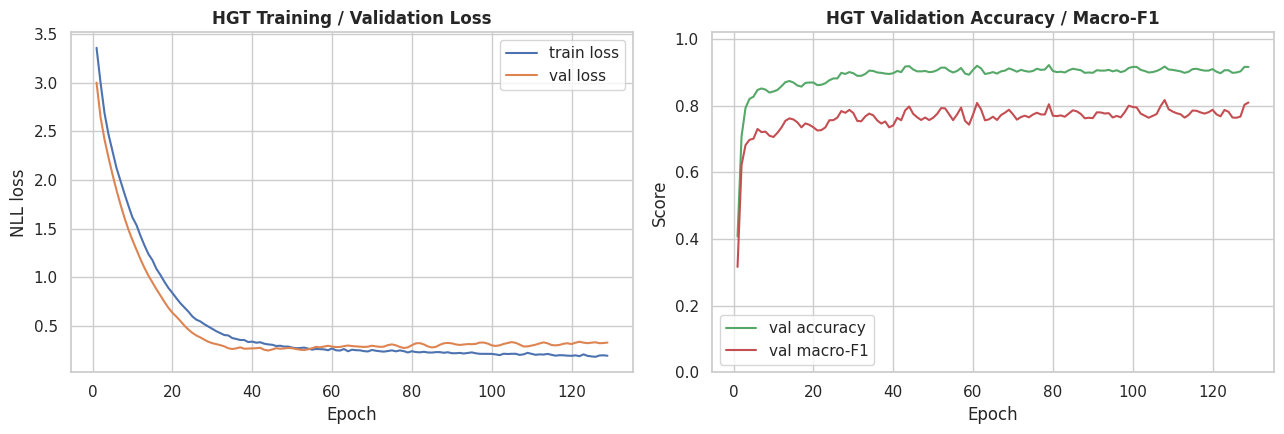

In [20]:
h = hgt_result["history"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(h["epoch"], h["train_loss"], label="train loss", color="#4C72B0")
axes[0].plot(h["epoch"], h["val_loss"], label="val loss", color="#DD8452")
axes[0].set_title("HGT Training / Validation Loss")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("NLL loss"); axes[0].legend()

axes[1].plot(h["epoch"], h["val_acc"], label="val accuracy", color="#55A868")
axes[1].plot(h["epoch"], h["val_macro_f1"], label="val macro-F1", color="#C44E52")
axes[1].set_title("HGT Validation Accuracy / Macro-F1")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Score"); axes[1].legend()
axes[1].set_ylim(0, 1.02)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_hgt_training_curves.png", bbox_inches="tight")
plt.show()


### 6.4 Test-set confusion matrix (HGT)

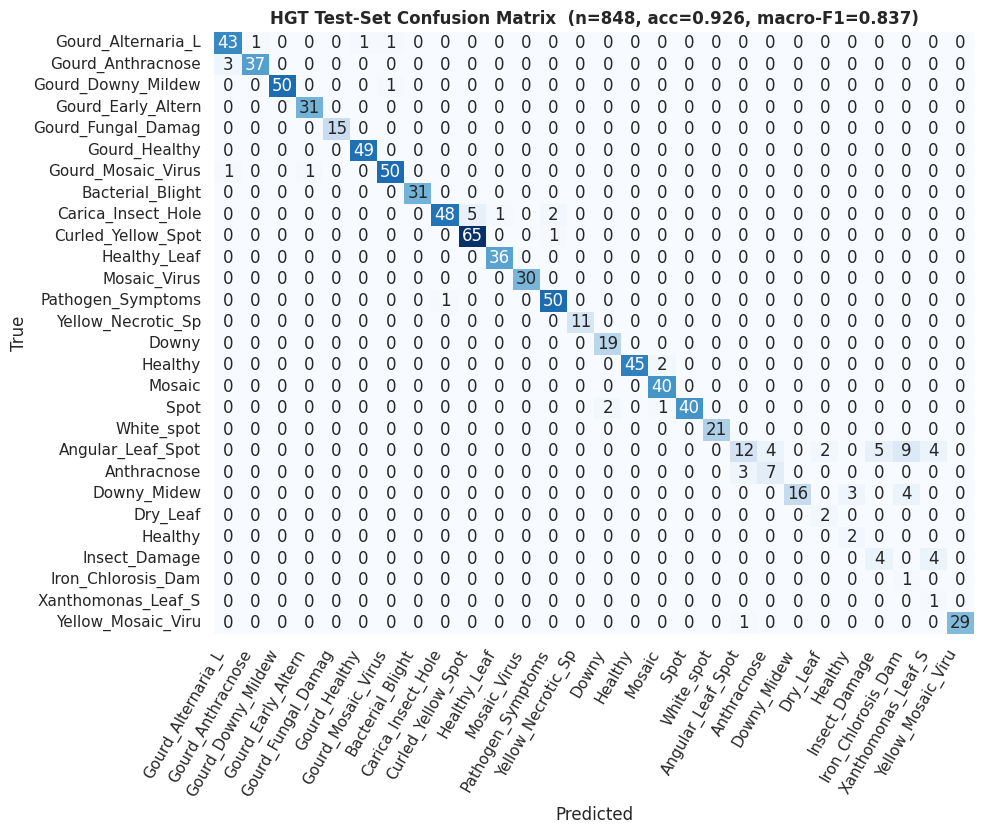

In [21]:
test_pred, test_true = hgt_result["test_pred"], hgt_result["test_true"]
present_classes = sorted(set(test_true.tolist()) | set(test_pred.tolist()))
cm = np.zeros((len(present_classes), len(present_classes)), dtype=int)
cls_pos = {c: i for i, c in enumerate(present_classes)}
for t, p in zip(test_true, test_pred):
    cm[cls_pos[t], cls_pos[p]] += 1

fig, ax = plt.subplots(figsize=(10, 8.5))
labels_short = [id_to_class[c].split("_", 1)[-1][:18] for c in present_classes]
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
            xticklabels=labels_short, yticklabels=labels_short, cbar=False)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title(f"HGT Test-Set Confusion Matrix  (n={len(test_true)}, "
             f"acc={hgt_result['test_acc']:.3f}, macro-F1={hgt_result['test_macro_f1']:.3f})")
plt.xticks(rotation=60, ha="right"); plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "06_confusion_matrix.png", bbox_inches="tight")
plt.show()


## 7. Baseline Comparison — Does the Relational Graph Help?

To isolate what the heterogeneous graph structure actually contributes, we
train a plain multinomial logistic-regression classifier on the **exact
same leakage-safe split** and the **exact same per-image feature vectors**
— the only difference is this baseline has **no graph**: no crop/disease/
disease_category nodes, no relational message passing, just the raw
per-image features mapped straight to a class.

If HGT does meaningfully better than this, that's evidence the
crop↔disease↔category relational structure adds signal beyond what's
already in each image's own pixel statistics. If it doesn't, that's
useful, honest information too — see the caveat in Section 8.

                                        Model  Val Accuracy  Test Accuracy  Test Macro-F1
Logistic Regression (features only, no graph)      0.895089       0.917453       0.806914
                       HGT (relational graph)      0.921875       0.925708       0.837388


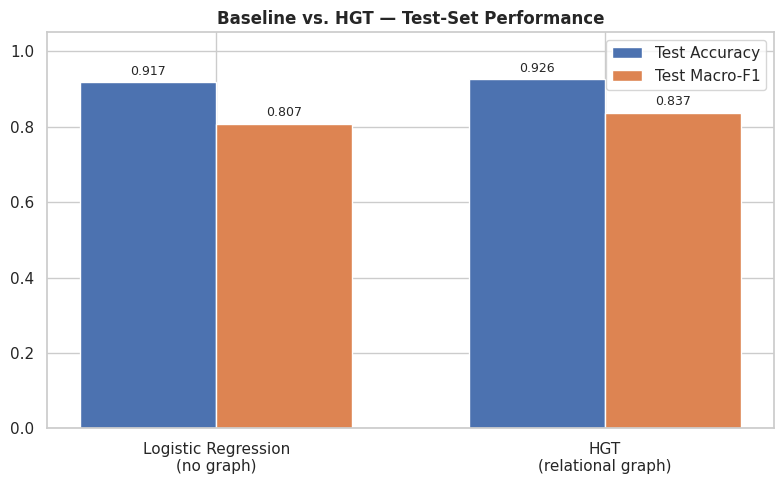

In [22]:
def train_baseline(scaled_feats, labels, train_mask, val_mask, test_mask, n_classes, seed=RNG_SEED):
    X_train, y_train = scaled_feats[train_mask], labels[train_mask]
    X_val, y_val = scaled_feats[val_mask], labels[val_mask]
    X_test, y_test = scaled_feats[test_mask], labels[test_mask]

    clf = LogisticRegression(max_iter=2000, random_state=seed)
    clf.fit(X_train, y_train)

    val_pred, test_pred = clf.predict(X_val), clf.predict(X_test)
    return {
        "clf": clf,
        "val_acc": float((val_pred == y_val).mean()), "val_macro_f1": macro_f1(y_val, val_pred, n_classes),
        "test_acc": float((test_pred == y_test).mean()), "test_macro_f1": macro_f1(y_test, test_pred, n_classes),
        "test_pred": test_pred, "test_true": y_test,
    }

baseline_result = train_baseline(scaled_feats, labels, train_mask, val_mask, test_mask, N_CLASSES)

comparison = pd.DataFrame({
    "Model": ["Logistic Regression (features only, no graph)", "HGT (relational graph)"],
    "Val Accuracy": [baseline_result["val_acc"], hgt_result["best_val_acc"]],
    "Test Accuracy": [baseline_result["test_acc"], hgt_result["test_acc"]],
    "Test Macro-F1": [baseline_result["test_macro_f1"], hgt_result["test_macro_f1"]],
})
print(comparison.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(2); width = 0.35
ax.bar(x - width/2, comparison["Test Accuracy"], width, label="Test Accuracy", color="#4C72B0")
ax.bar(x + width/2, comparison["Test Macro-F1"], width, label="Test Macro-F1", color="#DD8452")
ax.set_xticks(x); ax.set_xticklabels(["Logistic Regression\n(no graph)", "HGT\n(relational graph)"])
ax.set_ylim(0, 1.05)
ax.set_title("Baseline vs. HGT — Test-Set Performance")
ax.legend()
for i, (acc, f1) in enumerate(zip(comparison["Test Accuracy"], comparison["Test Macro-F1"])):
    ax.text(i - width/2, acc + 0.02, f"{acc:.3f}", ha="center", fontsize=9)
    ax.text(i + width/2, f1 + 0.02, f"{f1:.3f}", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "07_baseline_vs_hgt.png", bbox_inches="tight")
plt.show()


### 7.1 Per-class test metrics (HGT)

In [23]:
rows = []
for c in present_classes:
    y_true_bin = (test_true == c)
    y_pred_bin = (test_pred == c)
    tp = int((y_true_bin & y_pred_bin).sum())
    fp = int((~y_true_bin & y_pred_bin).sum())
    fn = int((y_true_bin & ~y_pred_bin).sum())
    support = int(y_true_bin.sum())
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    rec = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 0.0 if (prec + rec) == 0 else 2 * prec * rec / (prec + rec)
    rows.append({"class_name": id_to_class[c], "support": support,
                 "precision": round(prec, 3), "recall": round(rec, 3), "f1": round(f1, 3)})

per_class_df = pd.DataFrame(rows).sort_values("support", ascending=False)
print(per_class_df.to_string(index=False))


                               class_name  support  precision  recall    f1
                Papaya_Curled_Yellow_Spot       66      0.929   0.985 0.956
                Papaya_Carica_Insect_Hole       56      0.980   0.857 0.914
                Bottle_Gourd_Mosaic_Virus       52      0.962   0.962 0.962
                Bottle_Gourd_Downy_Mildew       51      1.000   0.980 0.990
                 Papaya_Pathogen_Symptoms       51      0.943   0.980 0.962
                     Bottle_Gourd_Healthy       49      0.980   1.000 0.990
                           Tomato_Healthy       47      1.000   0.957 0.978
      Bottle_Gourd_Alternaria_Leaf_Blight       46      0.915   0.935 0.925
                              Tomato_Spot       43      1.000   0.930 0.964
                            Tomato_Mosaic       40      0.930   1.000 0.964
                 Bottle_Gourd_Anthracnose       40      0.974   0.925 0.949
                      Papaya_Healthy_Leaf       36      0.973   1.000 0.986
            

## 8. Discussion & Limitations

This section collects the caveats already surfaced by the diagnostics above,
in one place, rather than leaving them scattered across individual result
cells.

- **Effect size vs. baseline.** The relational graph's improvement over the
  feature-only logistic-regression baseline (Section 7) is small in absolute
  terms. A single-seed comparison is not sufficient to establish that this
  gap reflects a real effect of the graph structure rather than run-to-run
  variance; multi-seed replication with a reported mean and spread is the
  natural next step before treating the gap as a settled result.
- **Overfitting signal in the training curves.** Section 6.3's loss curves
  show validation loss rising well before `n_epochs` is reached, while the
  reported checkpoint is selected by best validation accuracy rather than
  best validation loss. The final evaluation is therefore not taken from
  the most-overfit epoch, but the divergence itself indicates the model's
  calibration degrades with continued training, which is worth accounting
  for in any downstream use of predicted probabilities.
- **Feature extractor dependency.** All downstream components (the k-NN
  `similar_to` edges, the baseline, and the HGT leaf-node inputs) are built
  on the same fine-tuned backbone feature bank (Section 3.1). Any limitation
  in that fine-tuning (despite the 400-epoch maximum and patience-20 early stopping) propagates into
  every result reported afterward.
- **Single dataset, single split realization.** All results reflect one
  leakage-safe split of Agri-Vision4. Generalization to other multi-crop
  disease datasets, or sensitivity to the specific split/near-duplicate
  threshold chosen in Section 2, has not been evaluated here.
